<a href="https://colab.research.google.com/github/salihaliyi73/XAI_for_LGIT_YOLOv5/blob/main/XAI_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import auth
auth.authenticate_user()

In [25]:
import os
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path
from utils.augmentations import letterbox

print("All required libraries imported successfully!")
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)

All required libraries imported successfully!
OpenCV: 4.14.0
NumPy: 2.4.6
PyTorch: 2.14.1+cu130


In [8]:
from google.colab import auth
auth.authenticate_user()

from google.auth import default
from googleapiclient.discovery import build

credentials, project = default()

service = build('drive', 'v3', credentials=credentials)

results = service.files().list(
    pageSize=10,
    fields="files(id, name, mimeType)"
).execute()

for file in results.get('files', []):
    print(file['name'], file['mimeType'])

XAI_Evaluation.ipynb application/vnd.google.colaboratory
Evaluation_Results application/vnd.google-apps.folder
Notebooks application/vnd.google-apps.folder
Model_Files application/vnd.google-apps.folder
XAI_Gastrointestinal_First_Project application/vnd.google-apps.folder
test_dataset.zip application/x-zip-compressed
Copy of YOLOv5_GradCAM_Gastrointestinal_XAI.ipynb application/vnd.google.colaboratory
YOLOv5_GradCAM_Gastrointestinal_XAI.ipynb application/vnd.google.colaboratory
SALIH ALIYI application/vnd.google-apps.folder
CERTIFICATION application/vnd.google-apps.folder


Verify the model files

In [9]:
from googleapiclient.http import MediaIoBaseDownload
import io

results = service.files().list(
    q="name = 'Model_Files' and mimeType = 'application/vnd.google-apps.folder' and trashed = false",
    fields="files(id, name)"
).execute()

print(results['files'])

[{'id': '14YdF0ZNDkMshMl-WXN8Y8sgLkswnzB05', 'name': 'Model_Files'}]


List the contents of Model_Files

In [10]:
MODEL_FOLDER_ID = '14YdF0ZNDkMshMl-WXN8Y8sgLkswnzB05'

results = service.files().list(
    q=f"'{MODEL_FOLDER_ID}' in parents and trashed = false",
    fields="files(id, name, mimeType, size)"
).execute()

for file in results.get('files', []):
    print(file)

{'mimeType': 'application/x-zip', 'size': '14331061', 'id': '110dpNM1Zc1I0O_Q74u-m_FC_PE5nF7ub', 'name': 'best.pt'}
{'mimeType': 'application/octet-stream', 'size': '326', 'id': '1W3fKtM3hX3YyXUn2AcxwIL-UZ_ddGIAN', 'name': 'Lgit.yaml'}


Download both files into Colab

In [11]:
import os
import io
from googleapiclient.http import MediaIoBaseDownload

os.makedirs('/content/XAI_Project/Model_Files', exist_ok=True)

files_to_download = {
    'best.pt': '110dpNM1Zc1I0O_Q74u-m_FC_PE5nF7ub',
    'Lgit.yaml': '1W3fKtM3hX3YyXUn2AcxwIL-UZ_ddGIAN'
}

for filename, file_id in files_to_download.items():
    request = service.files().get_media(fileId=file_id)

    with open(f'/content/XAI_Project/Model_Files/{filename}', 'wb') as f:
        downloader = MediaIoBaseDownload(f, request)
        done = False
        while not done:
            status, done = downloader.next_chunk()

    print(f"Downloaded: {filename}")

print("\nFiles:", os.listdir('/content/XAI_Project/Model_Files'))

Downloaded: best.pt
Downloaded: Lgit.yaml

Files: ['best.pt', 'Lgit.yaml']


Locate test_dataset.zip in Google Drive

In [12]:
results = service.files().list(
    q="name = 'test_dataset.zip' and trashed = false",
    fields="files(id, name, size)"
).execute()

for file in results.get('files', []):
    print(file)

{'size': '137658995', 'id': '11NpASeFTrC7h_wZq6UF-raQAokvB6J2g', 'name': 'test_dataset.zip'}


Download and extract the dataset

In [13]:
import os
import zipfile
from googleapiclient.http import MediaIoBaseDownload

ZIP_ID = '11NpASeFTrC7h_wZq6UF-raQAokvB6J2g'
ZIP_PATH = '/content/XAI_Project/test_dataset.zip'

os.makedirs('/content/XAI_Project', exist_ok=True)

request = service.files().get_media(fileId=ZIP_ID)

with open(ZIP_PATH, 'wb') as f:
    downloader = MediaIoBaseDownload(f, request)
    done = False

    while not done:
        status, done = downloader.next_chunk()
        if status:
            print(f"Download progress: {int(status.progress() * 100)}%")

print("Dataset downloaded successfully!")
print("File size:", os.path.getsize(ZIP_PATH) / (1024 * 1024), "MB")

Download progress: 76%
Download progress: 100%
Dataset downloaded successfully!
File size: 131.2818479537964 MB


Extract the dataset

In [14]:
import zipfile
import os

EXTRACT_PATH = '/content/XAI_Project'

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Dataset extracted successfully!")

for root, dirs, files in os.walk(EXTRACT_PATH):
    print(root, "->", len(files), "files")

Dataset extracted successfully!
/content/XAI_Project -> 1 files
/content/XAI_Project/Model_Files -> 2 files
/content/XAI_Project/test_dataset -> 0 files
/content/XAI_Project/test_dataset/test_img -> 1200 files
/content/XAI_Project/test_dataset/test_label -> 1200 files


Verify image and label filenames

In [15]:
import os

IMAGE_DIR = '/content/XAI_Project/test_dataset/test_img'
LABEL_DIR = '/content/XAI_Project/test_dataset/test_label'

images = sorted([
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
])

labels = sorted([
    f for f in os.listdir(LABEL_DIR)
    if f.lower().endswith('.txt')
])

image_names = {os.path.splitext(f)[0] for f in images}
label_names = {os.path.splitext(f)[0] for f in labels}

print("Total images:", len(images))
print("Total labels:", len(labels))
print("Images without labels:", len(image_names - label_names))
print("Labels without images:", len(label_names - image_names))

print("\nFirst 5 images:", images[:5])
print("First 5 labels:", labels[:5])

Total images: 1200
Total labels: 1200
Images without labels: 0
Labels without images: 0

First 5 images: ['0013240d-bb50-4886-a616-e1995eb1a163.jpg', '00d37536-e0a0-4a19-ac89-d9658d7f821c.jpg', '01b2ec26-e814-4053-a820-37c9b703d47a.jpg', '0225440c-73b0-4c5e-b4b4-5bfe306834c9.jpg', '04827eb8-7b02-4e85-baa2-e55a6191f542.jpg']
First 5 labels: ['0013240d-bb50-4886-a616-e1995eb1a163.txt', '00d37536-e0a0-4a19-ac89-d9658d7f821c.txt', '01b2ec26-e814-4053-a820-37c9b703d47a.txt', '0225440c-73b0-4c5e-b4b4-5bfe306834c9.txt', '04827eb8-7b02-4e85-baa2-e55a6191f542.txt']


# Prepare the YOLOv5 + Grad-CAM pipeline
Check the model and YAML files

In [16]:
import os

MODEL_PATH = '/content/XAI_Project/Model_Files/best.pt'
YAML_PATH = '/content/XAI_Project/Model_Files/Lgit.yaml'

print("Model exists:", os.path.exists(MODEL_PATH))
print("YAML exists:", os.path.exists(YAML_PATH))

print("\nYAML configuration:")
with open(YAML_PATH, 'r') as f:
    print(f.read())

Model exists: True
YAML exists: True

YAML configuration:

train: /content/tarain_dataset/images/train # train images (relative to 'path') 128 images
val: /content/tarain_dataset/images/val  # val images (relative to 'path') 128 images

# Classes
nc: 8  # number of classes
names: ['polyps','cecum','inadequate','normal','impaction','retroflexion','UC','hemorrhoid']  # class names





Define the test dataset paths first

In [17]:
TEST_IMAGE_DIR = '/content/XAI_Project/test_dataset/test_img'
TEST_LABEL_DIR = '/content/XAI_Project/test_dataset/test_label'
MODEL_PATH = '/content/XAI_Project/Model_Files/best.pt'

NUM_CLASSES = 8

CLASS_NAMES = [
    'polyps', 'cecum', 'inadequate', 'normal',
    'impaction', 'retroflexion', 'UC', 'hemorrhoid'
]

print("Test images:", TEST_IMAGE_DIR)
print("Test labels:", TEST_LABEL_DIR)
print("Model:", MODEL_PATH)

Test images: /content/XAI_Project/test_dataset/test_img
Test labels: /content/XAI_Project/test_dataset/test_label
Model: /content/XAI_Project/Model_Files/best.pt


Before loading YOLOv5

In [18]:
import os

print("YOLOv5 folder exists:",
      os.path.exists('/content/yolov5'))

print("Current directory:", os.getcwd())

YOLOv5 folder exists: False
Current directory: /content


Let's prepare the original YOLOv5 environment

In [19]:
%cd /content

!git clone https://github.com/ultralytics/yolov5.git

%cd /content/yolov5

!pip install -qr requirements.txt

/content
Cloning into 'yolov5'...
remote: Enumerating objects: 18881, done.
remote: Counting objects: 100% (410/410), done.
remote: Compressing objects: 100% (74/74), done.
remote: Total 18881 (delta 352), reused 336 (delta 336), pack-reused 18471 (from 3)
Receiving objects: 100% (18881/18881), 17.70 MiB | 14.59 MiB/s, done.
Resolving deltas: 100% (12886/12886), done.
/content/yolov5


In [20]:
import torch
import sys

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("YOLOv5 directory:", os.getcwd())

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
YOLOv5 directory: /content/yolov5


Load your trained YOLOv5 model

In [21]:
import torch
import sys
import os

sys.path.insert(0, '/content/yolov5')

MODEL_PATH = '/content/XAI_Project/Model_Files/best.pt'

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

model = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=False
)

print("Model loaded successfully!")
print("Model type:", type(model))
print("Device:", device)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Model loaded successfully!
Model type: <class 'dict'>
Device: cuda:0


In [22]:
print("Checkpoint keys:")
print(checkpoint.keys() if 'checkpoint' in globals() else model.keys())

ckpt = checkpoint if 'checkpoint' in globals() else model

for key in ['model', 'ema', 'epoch', 'optimizer']:
    if key in ckpt:
        print(key, ":", type(ckpt[key]))

Checkpoint keys:
dict_keys(['epoch', 'best_fitness', 'model', 'ema', 'updates', 'optimizer', 'wandb_id', 'date'])
model : <class 'models.yolo.DetectionModel'>
ema : <class 'NoneType'>
epoch : <class 'int'>
optimizer : <class 'NoneType'>


Extract the trained model

In [24]:
import torch

checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=False
)

model = checkpoint['model'].to(device)
model.float()
model.eval()

print("Model extracted successfully!")
print("Model type:", type(model))
print("Device:", next(model.parameters()).device)
print("Number of classes:", model.nc)

Model extracted successfully!
Model type: <class 'models.yolo.DetectionModel'>
Device: cuda:0
Number of classes: 8


Select the Grad-CAM target layer

In [26]:
# Inspect the Grad-CAM target layer

target_layer = model.model[23]

print("Target layer:", target_layer)
print("Layer type:", type(target_layer).__name__)
print("Total model layers:", len(model.model))

Target layer: C3(
  (cv1): Conv(
    (conv): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(256, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
    (act): SiLU(inplace=True)
  )
  (cv2): Conv(
    (conv): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(256, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
    (act): SiLU(inplace=True)
  )
  (cv3): Conv(
    (conv): Conv2d(512, 512, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(512, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
    (act): SiLU(inplace=True)
  )
  (m): Sequential(
    (0): Bottleneck(
      (cv1): Conv(
        (conv): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(256, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (cv2

Register the Grad-CAM hooks

In [27]:
# Store activations and gradients
activations = []
gradients = []

def forward_hook(module, input, output):
    activations.append(output)

def backward_hook(module, grad_input, grad_output):
    gradients.append(grad_output[0])

# Register hooks on the target layer
forward_handle = target_layer.register_forward_hook(forward_hook)
backward_handle = target_layer.register_full_backward_hook(backward_hook)

print("Grad-CAM hooks registered successfully!")

Grad-CAM hooks registered successfully!


Test image preprocessing

In [28]:
# Select one test image
image_files = sorted([
    f for f in os.listdir(TEST_IMAGE_DIR)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
])

test_image_path = os.path.join(TEST_IMAGE_DIR, image_files[0])

# Read original image
original_image = cv2.imread(test_image_path)
original_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)

# YOLOv5 preprocessing
img = letterbox(original_image, new_shape=320)[0]
img = img.transpose((2, 0, 1))
img = np.ascontiguousarray(img)

# Convert to PyTorch tensor
input_tensor = torch.from_numpy(img).to(device).float() / 255.0
input_tensor = input_tensor.unsqueeze(0)

print("Image:", image_files[0])
print("Original image shape:", original_image.shape)
print("Input tensor shape:", input_tensor.shape)
print("Input device:", input_tensor.device)

Image: 0013240d-bb50-4886-a616-e1995eb1a163.jpg
Original image shape: (531, 633, 3)
Input tensor shape: torch.Size([1, 3, 288, 320])
Input device: cuda:0


Run a forward pass

In [29]:
# Clear previous hook outputs
activations.clear()
gradients.clear()

# Forward pass
model.zero_grad()
output = model(input_tensor)

print("Forward pass completed!")
print("Number of captured activations:", len(activations))
print("Activation shape:", activations[0].shape)

Forward pass completed!
Number of captured activations: 1
Activation shape: torch.Size([1, 512, 9, 10])


Select the prediction score for Grad-CAM

In [30]:
# Inspect model output
print("Output type:", type(output))
print("Number of output elements:", len(output))

for i, item in enumerate(output):
    if torch.is_tensor(item):
        print(f"Output[{i}] shape:", item.shape)
    elif isinstance(item, list):
        print(f"Output[{i}] is a list with {len(item)} elements")
        for j, feature in enumerate(item):
            print(f"  Feature[{j}] shape:", feature.shape)
    else:
        print(f"Output[{i}] type:", type(item))

Output type: <class 'tuple'>
Number of output elements: 2
Output[0] shape: torch.Size([1, 5670, 13])
Output[1] is a list with 3 elements
  Feature[0] shape: torch.Size([1, 3, 36, 40, 13])
  Feature[1] shape: torch.Size([1, 3, 18, 20, 13])
  Feature[2] shape: torch.Size([1, 3, 9, 10, 13])


Inspect the predictions

In [31]:
# Inspect the decoded predictions
predictions = output[0][0]

print("Predictions shape:", predictions.shape)
print("First prediction:", predictions[0])
print("Objectness score:", predictions[0, 4].item())
print("Class scores:", predictions[0, 5:].detach().cpu().numpy())

Predictions shape: torch.Size([5670, 13])
First prediction: tensor([8.51735e+00, 5.94372e+00, 1.64075e+01, 1.02084e+01, 8.31877e-08, 8.63658e-02, 1.72116e-02, 3.09929e-02, 1.01147e-02, 7.87015e-01, 1.86295e-02, 1.33690e-02, 2.08696e-02], device='cuda:0')
Objectness score: 8.318772160009757e-08
Class scores: [   0.086366    0.017212    0.030993    0.010115     0.78701     0.01863    0.013369     0.02087]


Find the strongest prediction

In [32]:
# Calculate confidence for every candidate
objectness = predictions[:, 4]
class_scores = predictions[:, 5:]

best_class_scores, best_classes = class_scores.max(dim=1)

confidence_scores = objectness * best_class_scores

# Find the candidate with the highest confidence
best_index = confidence_scores.argmax()

selected_class = best_classes[best_index].item()
selected_confidence = confidence_scores[best_index]

# Keep the target score connected to the computational graph
target_score = (
    predictions[best_index, 4] *
    predictions[best_index, 5 + selected_class]
)

print("Selected prediction index:", best_index.item())
print("Predicted class:", CLASS_NAMES[selected_class])
print("Combined confidence:", selected_confidence.item())
print("Target score requires gradient:", target_score.requires_grad)

Selected prediction index: 5426
Predicted class: inadequate
Combined confidence: 0.7895070314407349
Target score requires gradient: False


Repeat the forward pass with gradient tracking

In [33]:
# Clear previously captured values
activations.clear()
gradients.clear()

# Enable gradient tracking
model.zero_grad()

with torch.enable_grad():
    output = model(input_tensor)

    predictions = output[0][0]

    objectness = predictions[:, 4]
    class_scores = predictions[:, 5:]

    best_class_scores, best_classes = class_scores.max(dim=1)
    confidence_scores = objectness * best_class_scores

    best_index = confidence_scores.argmax()
    selected_class = best_classes[best_index].item()

    target_score = (
        predictions[best_index, 4] *
        predictions[best_index, 5 + selected_class]
    )

print("Selected prediction:", best_index.item())
print("Selected class:", CLASS_NAMES[selected_class])
print("Target score:", target_score.item())
print("Requires gradient:", target_score.requires_grad)
print("Captured activations:", len(activations))

Selected prediction: 5426
Selected class: inadequate
Target score: 0.7895070314407349
Requires gradient: False
Captured activations: 1


Check gradient settings

In [34]:
print("Gradient tracking enabled:", torch.is_grad_enabled())
print("Input requires gradient:", input_tensor.requires_grad)

# Check model parameters
trainable_parameters = sum(
    p.requires_grad for p in model.parameters()
)

total_parameters = sum(
    1 for p in model.parameters()
)

print("Trainable parameters:", trainable_parameters)
print("Total parameters:", total_parameters)

# Check whether the target layer is connected to the graph
print("Activation requires gradient:", activations[0].requires_grad)
print("Activation has grad_fn:", activations[0].grad_fn)
print("Target score requires gradient:", target_score.requires_grad)

Gradient tracking enabled: True
Input requires gradient: False
Trainable parameters: 0
Total parameters: 177
Activation requires gradient: False
Activation has grad_fn: None
Target score requires gradient: False


Enable gradients for the model

In [35]:
# Enable gradients for all model parameters
for parameter in model.parameters():
    parameter.requires_grad_(True)

# Enable gradients for the input
input_tensor = input_tensor.detach().requires_grad_(True)

# Keep the model in evaluation mode
model.eval()

print("Trainable parameters:",
      sum(p.requires_grad for p in model.parameters()))

print("Input requires gradient:", input_tensor.requires_grad)

Trainable parameters: 177
Input requires gradient: True


Repeat the forward pass

In [36]:
# Clear previously captured activations and gradients
activations.clear()
gradients.clear()

model.zero_grad()

# Forward pass with gradient tracking
output = model(input_tensor)

predictions = output[0][0]

# Select the strongest prediction
objectness = predictions[:, 4]
class_scores = predictions[:, 5:]

best_class_scores, best_classes = class_scores.max(dim=1)
confidence_scores = objectness * best_class_scores

best_index = confidence_scores.argmax()
selected_class = best_classes[best_index].item()

target_score = (
    predictions[best_index, 4] *
    predictions[best_index, 5 + selected_class]
)

print("Selected prediction:", best_index.item())
print("Selected class:", CLASS_NAMES[selected_class])
print("Target score:", target_score.item())
print("Target score requires gradient:", target_score.requires_grad)
print("Activation requires gradient:", activations[0].requires_grad)
print("Activation grad_fn:", activations[0].grad_fn)

Selected prediction: 5426
Selected class: inadequate
Target score: 0.7895070314407349
Target score requires gradient: True
Activation requires gradient: True
Activation grad_fn: <SiluBackward0 object at 0x7897dff71f60>


Backpropagation and gradient capture

In [37]:
# Backpropagate the selected prediction score
model.zero_grad()
target_score.backward()

print("Backpropagation completed!")
print("Number of captured gradients:", len(gradients))

if gradients:
    print("Gradient shape:", gradients[0].shape)
    print("Gradient requires gradient:", gradients[0].requires_grad)
    print("Gradient mean:", gradients[0].mean().item())
    print("Gradient absolute mean:", gradients[0].abs().mean().item())

Backpropagation completed!
Number of captured gradients: 1
Gradient shape: torch.Size([1, 512, 9, 10])
Gradient requires gradient: False
Gradient mean: -1.8519634977565147e-05
Gradient absolute mean: 0.00015644807717762887


Calculate the Grad-CAM heatmap

In [38]:
# Extract activations and gradients
feature_maps = activations[0]
grads = gradients[0]

# Calculate channel weights
weights = grads.mean(dim=(2, 3), keepdim=True)

# Weighted combination of feature maps
cam = (weights * feature_maps).sum(dim=1, keepdim=True)

# Apply ReLU
cam = torch.relu(cam)

# Normalize Grad-CAM
cam = cam.squeeze()

cam = cam - cam.min()
cam = cam / (cam.max() + 1e-8)

# Convert to NumPy
cam = cam.detach().cpu().numpy()

print("Grad-CAM generated successfully!")
print("Heatmap shape:", cam.shape)
print("Minimum value:", cam.min())
print("Maximum value:", cam.max())

Grad-CAM generated successfully!
Heatmap shape: (9, 10)
Minimum value: 0.0
Maximum value: 0.99999857


Resize and visualize the heatmap

Resized heatmap shape: (531, 633)
Heatmap color shape: (531, 633, 3)
Overlay shape: (531, 633, 3)


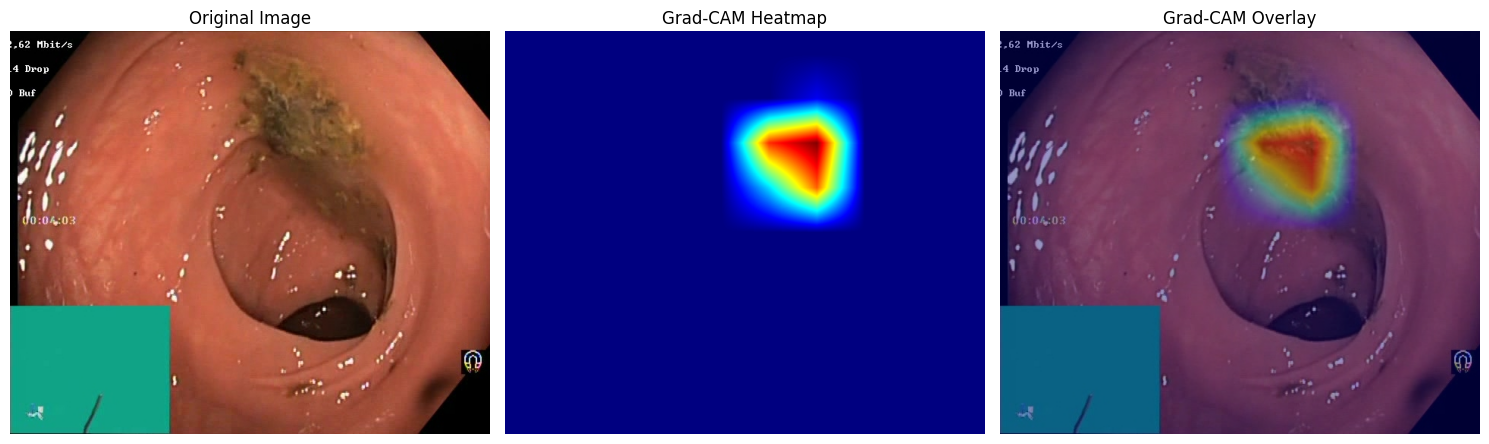

In [39]:
# Resize Grad-CAM to original image dimensions
height, width = original_image.shape[:2]

cam_resized = cv2.resize(
    cam,
    (width, height),
    interpolation=cv2.INTER_LINEAR
)

# Convert heatmap to 8-bit
cam_uint8 = np.uint8(255 * cam_resized)

# Apply JET colormap
heatmap_color = cv2.applyColorMap(
    cam_uint8,
    cv2.COLORMAP_JET
)

# Convert BGR to RGB
heatmap_color = cv2.cvtColor(
    heatmap_color,
    cv2.COLOR_BGR2RGB
)

# Create overlay
overlay = cv2.addWeighted(
    original_image,
    0.6,
    heatmap_color,
    0.4,
    0
)

print("Resized heatmap shape:", cam_resized.shape)
print("Heatmap color shape:", heatmap_color.shape)
print("Overlay shape:", overlay.shape)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_color)
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

Generate the detection image

In [40]:
from utils.general import non_max_suppression, scale_boxes
from utils.plots import Annotator, colors

# Apply NMS to model predictions
detections = non_max_suppression(
    output[0],
    conf_thres=0.25,
    iou_thres=0.45
)[0]

# Create a copy of the original image
detection_image = original_image.copy()

if len(detections):
    # Scale boxes from model input dimensions to original image dimensions
    detections[:, :4] = scale_boxes(
        input_tensor.shape[2:],
        detections[:, :4],
        original_image.shape
    ).round()

    annotator = Annotator(detection_image)

    for *xyxy, conf, cls in detections:
        class_id = int(cls)
        label = f'{CLASS_NAMES[class_id]} {conf:.2f}'

        annotator.box_label(
            xyxy,
            label,
            color=colors(class_id, True)
        )

    detection_image = annotator.result()

print("Number of detections:", len(detections))

plt.figure(figsize=(8, 6))
plt.imshow(detection_image)
plt.title("YOLOv5 Detection")
plt.axis("off")
plt.show()

Number of detections: 1


Combine the four panels horizontally

In [41]:
# Create a four-panel visualization
fig, axes = plt.subplots(1, 4, figsize=(24, 6))

images = [
    original_image,
    detection_image,
    heatmap_color,
    overlay
]

titles = [
    "Original Image",
    "YOLOv5 Detection",
    "Grad-CAM Heatmap",
    "Grad-CAM Overlay"
]

for ax, image, title in zip(axes, images, titles):
    ax.imshow(image)
    ax.set_title(title, fontsize=13)
    ax.axis("off")

plt.tight_layout()
plt.show()

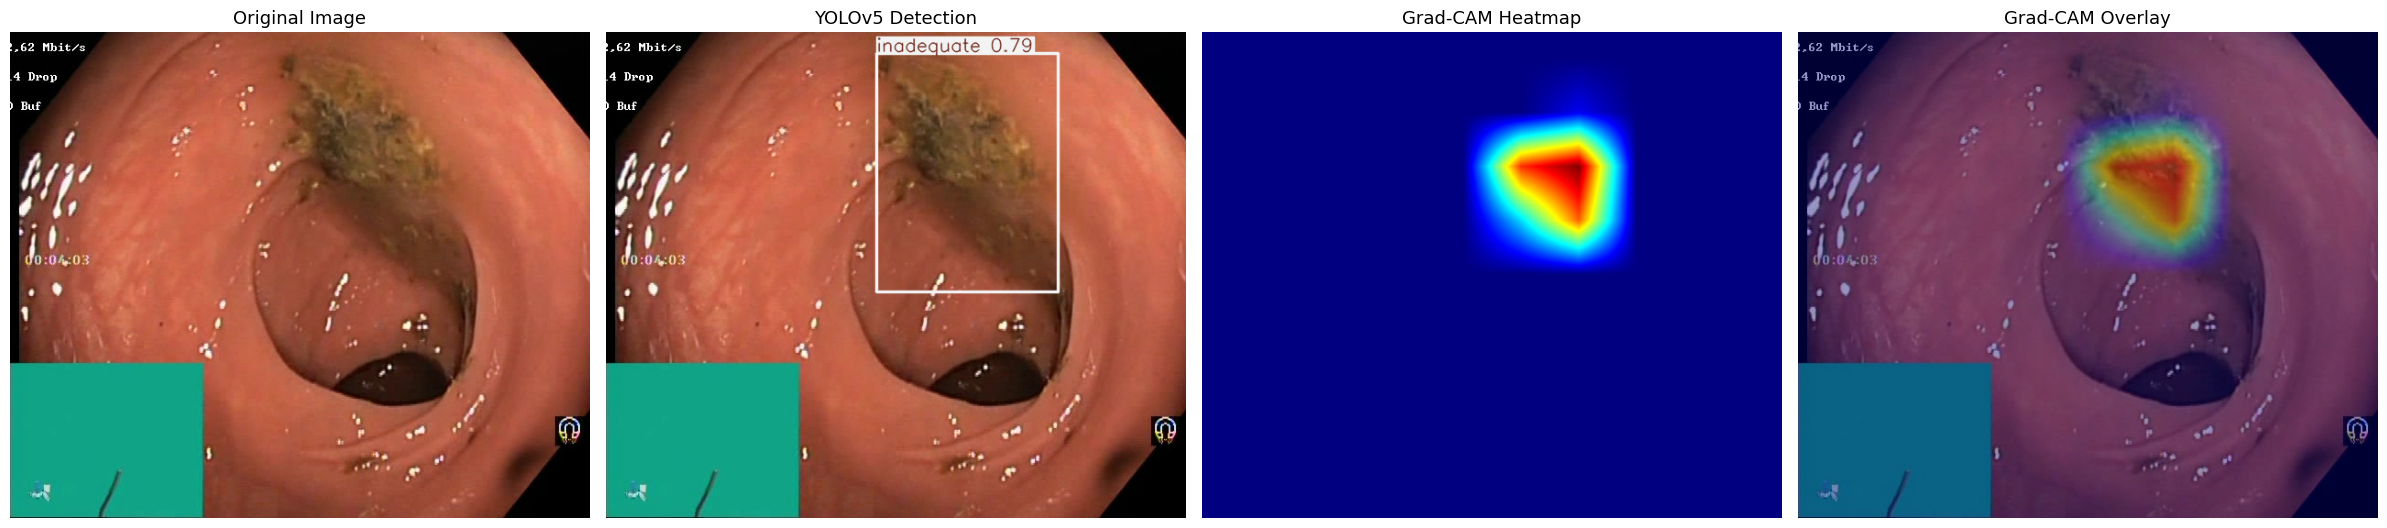

In [42]:
from IPython.display import display

fig, axes = plt.subplots(1, 4, figsize=(24, 7))

images = [
    original_image,
    detection_image,
    heatmap_color,
    overlay
]

titles = [
    "Original Image",
    "YOLOv5 Detection",
    "Grad-CAM Heatmap",
    "Grad-CAM Overlay"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img)
    ax.set_title(title, fontsize=13)
    ax.axis("off")

plt.tight_layout()
display(fig)
plt.close(fig)

Save the four-panel figure and raw Grad-CAM

In [43]:
# Create evaluation results directory
RESULTS_DIR = "/content/XAI_Project/Evaluation_Results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# Save the four-panel figure
output_figure = os.path.join(
    RESULTS_DIR,
    "0013240d-bb50-4886-a616-e1995eb1a163_four_panel.png"
)

fig, axes = plt.subplots(1, 4, figsize=(24, 7))

images = [
    original_image,
    detection_image,
    heatmap_color,
    overlay
]

titles = [
    "Original Image",
    "YOLOv5 Detection",
    "Grad-CAM Heatmap",
    "Grad-CAM Overlay"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img)
    ax.set_title(title, fontsize=13)
    ax.axis("off")

plt.tight_layout()
fig.savefig(output_figure, dpi=300, bbox_inches="tight")
plt.close(fig)

# Save the numerical Grad-CAM heatmap
output_cam = os.path.join(
    RESULTS_DIR,
    "0013240d-bb50-4886-a616-e1995eb1a163_gradcam.npy"
)

np.save(output_cam, cam)

print("Four-panel figure saved:", output_figure)
print("Raw Grad-CAM saved:", output_cam)
print("Results directory:", RESULTS_DIR)

Four-panel figure saved: /content/XAI_Project/Evaluation_Results/0013240d-bb50-4886-a616-e1995eb1a163_four_panel.png
Raw Grad-CAM saved: /content/XAI_Project/Evaluation_Results/0013240d-bb50-4886-a616-e1995eb1a163_gradcam.npy
Results directory: /content/XAI_Project/Evaluation_Results


Create the evaluation folders and verify the dataset

In [44]:
# Create organized output directories
FIGURES_DIR = os.path.join(RESULTS_DIR, "Four_Panel_Figures")
CAM_DIR = os.path.join(RESULTS_DIR, "GradCAM_Heatmaps")
METRICS_DIR = os.path.join(RESULTS_DIR, "Metrics")

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(CAM_DIR, exist_ok=True)
os.makedirs(METRICS_DIR, exist_ok=True)

# Collect image and label filenames
image_files = sorted([
    f for f in os.listdir(TEST_IMAGE_DIR)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
])

label_files = sorted([
    f for f in os.listdir(TEST_LABEL_DIR)
    if f.lower().endswith('.txt')
])

# Compare filenames without extensions
image_stems = {Path(f).stem for f in image_files}
label_stems = {Path(f).stem for f in label_files}

print("Number of test images:", len(image_files))
print("Number of label files:", len(label_files))
print("Images with matching labels:", len(image_stems & label_stems))
print("Images without labels:", len(image_stems - label_stems))
print("Labels without images:", len(label_stems - image_stems))

print("\nOutput folders created successfully!")

Number of test images: 1200
Number of label files: 1200
Images with matching labels: 1200
Images without labels: 0
Labels without images: 0

Output folders created successfully!


Let's create a backup of your current results

In [45]:
import shutil
from google.colab import files

backup_path = "/content/Evaluation_Results_Backup.zip"

shutil.make_archive(
    "/content/Evaluation_Results_Backup",
    "zip",
    RESULTS_DIR
)

files.download(backup_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Read one YOLO annotation file

In [46]:
# Select the first image and its corresponding label
sample_image = image_files[0]
sample_label_path = os.path.join(
    TEST_LABEL_DIR,
    Path(sample_image).stem + ".txt"
)

print("Image:", sample_image)
print("Label file:", sample_label_path)

with open(sample_label_path, "r") as f:
    label_content = f.read()

print("\nGround-truth annotation:")
print(label_content)

Image: 0013240d-bb50-4886-a616-e1995eb1a163.jpg
Label file: /content/XAI_Project/test_dataset/test_label/0013240d-bb50-4886-a616-e1995eb1a163.txt

Ground-truth annotation:
2 0.603476 0.249529 0.278041 0.423729



Create the reusable label-reading function

In [47]:
def read_yolo_labels(label_path, image_width, image_height):
    """
    Read YOLO-format labels and convert normalized
    bounding boxes into pixel coordinates.
    """

    boxes = []
    class_ids = []

    with open(label_path, "r") as file:
        for line in file:
            values = line.strip().split()

            if len(values) != 5:
                continue

            class_id = int(values[0])
            x_center, y_center, box_width, box_height = map(
                float, values[1:]
            )

            # Convert normalized coordinates to pixels
            x_center *= image_width
            y_center *= image_height
            box_width *= image_width
            box_height *= image_height

            # Convert center coordinates to corner coordinates
            x1 = int(x_center - box_width / 2)
            y1 = int(y_center - box_height / 2)
            x2 = int(x_center + box_width / 2)
            y2 = int(y_center + box_height / 2)

            # Keep coordinates inside the image
            x1 = max(0, min(x1, image_width - 1))
            y1 = max(0, min(y1, image_height - 1))
            x2 = max(0, min(x2, image_width - 1))
            y2 = max(0, min(y2, image_height - 1))

            boxes.append([x1, y1, x2, y2])
            class_ids.append(class_id)

    return boxes, class_ids

Test the function on your sample image

In [48]:
height, width = original_image.shape[:2]

gt_boxes, gt_classes = read_yolo_labels(
    sample_label_path,
    width,
    height
)

print("Image dimensions:", width, "x", height)
print("Ground-truth boxes:", gt_boxes)
print("Ground-truth classes:", gt_classes)

if gt_classes:
    print("Ground-truth class name:", CLASS_NAMES[gt_classes[0]])

Image dimensions: 633 x 531
Ground-truth boxes: [[294, 19, 470, 244]]
Ground-truth classes: [2]
Ground-truth class name: inadequate


Calculate Energy Inside Box

In [49]:
def calculate_energy_inside_box(cam, boxes):
    """
    Calculate the proportion of Grad-CAM energy
    located inside ground-truth bounding boxes.
    """

    total_energy = np.sum(cam)

    if total_energy <= 1e-8:
        return np.nan

    height, width = cam.shape
    combined_mask = np.zeros((height, width), dtype=bool)

    for x1, y1, x2, y2 in boxes:
        # Scale original-image coordinates to CAM coordinates
        cam_x1 = int(x1 * width / original_image.shape[1])
        cam_y1 = int(y1 * height / original_image.shape[0])
        cam_x2 = int(np.ceil(x2 * width / original_image.shape[1]))
        cam_y2 = int(np.ceil(y2 * height / original_image.shape[0]))

        combined_mask[
            cam_y1:cam_y2,
            cam_x1:cam_x2
        ] = True

    inside_energy = np.sum(cam[combined_mask])

    return float(inside_energy / total_energy)

In [50]:
energy_score = calculate_energy_inside_box(cam, gt_boxes)

print("Energy Inside Box:", energy_score)
print("Energy Inside Box (%):", energy_score * 100)

Energy Inside Box: 1.0
Energy Inside Box (%): 100.0


Pointing Game Accuracy

In [51]:
def calculate_pointing_game(cam, boxes):
    """
    Check whether the maximum Grad-CAM activation
    falls inside any ground-truth bounding box.
    """

    if cam.size == 0 or np.max(cam) <= 0:
        return np.nan

    # Find maximum activation location
    max_y, max_x = np.unravel_index(
        np.argmax(cam),
        cam.shape
    )

    cam_height, cam_width = cam.shape

    # Check whether maximum point is inside any box
    for x1, y1, x2, y2 in boxes:

        cam_x1 = x1 * cam_width / original_image.shape[1]
        cam_y1 = y1 * cam_height / original_image.shape[0]
        cam_x2 = x2 * cam_width / original_image.shape[1]
        cam_y2 = y2 * cam_height / original_image.shape[0]

        if cam_x1 <= max_x < cam_x2 and cam_y1 <= max_y < cam_y2:
            return 1

    return 0

In [52]:
pointing_score = calculate_pointing_game(cam, gt_boxes)

print("Pointing Game Accuracy:", pointing_score)

Pointing Game Accuracy: 1


# Prepare the Deletion and Insertion evaluation
define the evaluation settings.

In [53]:
# Deletion and Insertion evaluation settings

NUM_STEPS = 10
PERTURBATION_BASELINE = "blur"
BLUR_KERNEL_SIZE = 31

print("Evaluation settings")
print("Number of perturbation steps:", NUM_STEPS)
print("Baseline:", PERTURBATION_BASELINE)
print("Blur kernel:", BLUR_KERNEL_SIZE)

Evaluation settings
Number of perturbation steps: 10
Baseline: blur
Blur kernel: 31


In [54]:
NUM_STEPS = 10
PERTURBATION_BASELINE = "blur"
BLUR_KERNEL_SIZE = 31

print("Evaluation settings:")
print("Number of steps:", NUM_STEPS)
print("Baseline:", PERTURBATION_BASELINE)
print("Blur kernel:", BLUR_KERNEL_SIZE)

Evaluation settings:
Number of steps: 10
Baseline: blur
Blur kernel: 31


create the blurred baseline image

In [55]:
blurred_image = cv2.GaussianBlur(
    original_image,
    (BLUR_KERNEL_SIZE, BLUR_KERNEL_SIZE),
    0
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(blurred_image)
plt.title("Blurred Baseline")
plt.axis("off")

plt.tight_layout()
plt.show()

In [56]:
print("Original image shape:", original_image.shape)
print("Blurred image shape:", blurred_image.shape)
print("Blurred image created:", blurred_image is not None)

Original image shape: (531, 633, 3)
Blurred image shape: (531, 633, 3)
Blurred image created: True


array([[[  3,   3,   3],
        [  3,   3,   3],
        [  3,   3,   3],
        ...,
        [  2,   2,   2],
        [  2,   2,   2],
        [  2,   2,   2]],

       [[  3,   3,   3],
        [  3,   3,   3],
        [  3,   3,   3],
        ...,
        [  2,   2,   2],
        [  2,   2,   2],
        [  2,   2,   2]],

       [[  4,   4,   4],
        [  4,   4,   4],
        [  4,   4,   4],
        ...,
        [  2,   2,   2],
        [  2,   2,   2],
        [  2,   2,   2]],

       ...,

       [[ 38, 142, 118],
        [ 38, 142, 118],
        [ 37, 143, 118],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]],

       [[ 38, 142, 118],
        [ 38, 142, 118],
        [ 37, 142, 118],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]],

       [[ 38, 142, 118],
        [ 38, 142, 118],
        [ 37, 142, 118],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]]], shape=(531, 633, 3), dtype=uint8)
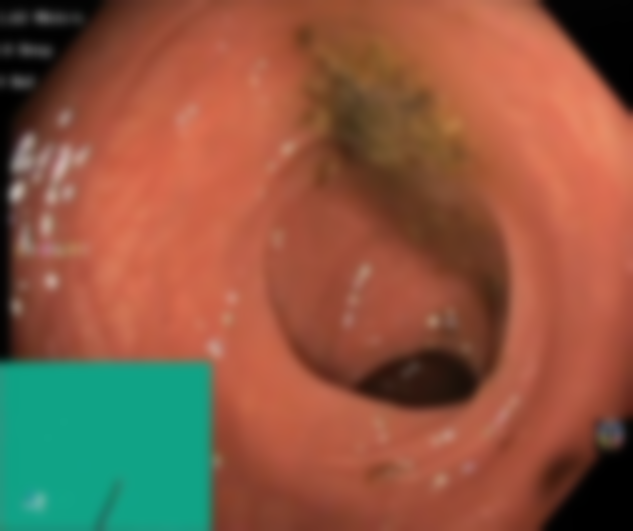

In [57]:
from IPython.display import display

display(blurred_image)

prepare the image regions for perturbation.

In [58]:
# Divide the original image into regions matching the CAM grid
image_height, image_width = original_image.shape[:2]
cam_height, cam_width = cam.shape

y_regions = np.array_split(np.arange(image_height), cam_height)
x_regions = np.array_split(np.arange(image_width), cam_width)

# Calculate the mean CAM importance of each region
region_scores = np.zeros((cam_height, cam_width))

for i, y in enumerate(y_regions):
    for j, x in enumerate(x_regions):
        region_scores[i, j] = np.mean(cam[i, j])

print("CAM grid:", cam.shape)
print("Number of image regions:", region_scores.size)
print("Highest region importance:", region_scores.max())

CAM grid: (9, 10)
Number of image regions: 90
Highest region importance: 0.9999985694885254


In [59]:
# Rank all CAM regions from highest to lowest importance
ranked_regions = np.argsort(region_scores.flatten())[::-1]

print("Total ranked regions:", len(ranked_regions))
print("Top 10 region indices:", ranked_regions[:10])
print("Top 10 importance scores:",
      region_scores.flatten()[ranked_regions[:10]])

Total ranked regions: 90
Top 10 region indices: [26 25 36 35 16 85 87 86 89 88]
Top 10 importance scores: [          1     0.83021     0.78154     0.34291     0.11199           0           0           0           0           0]


prepare the evaluation function

In [60]:
TARGET_INDEX = 5426
TARGET_CLASS = 2

def get_target_score(image):
    # Apply the same YOLOv5 preprocessing
    processed = letterbox(image, new_shape=320)[0]
    processed = processed.transpose((2, 0, 1))
    processed = np.ascontiguousarray(processed)

    tensor = torch.from_numpy(processed).to(device).float() / 255.0
    tensor = tensor.unsqueeze(0)

    # Inference without gradient calculation
    with torch.no_grad():
        prediction = model(tensor)[0]

    # Score the same candidate and class
    score = (
        prediction[0, TARGET_INDEX, 4]
        * prediction[0, TARGET_INDEX, 5 + TARGET_CLASS]
    )

    return float(score.item())

print("Original target score:", get_target_score(original_image))

Original target score: 0.7895070314407349


# Deletion evaluation
create a function that replaces selected regions

In [61]:
def replace_regions(source_image, replacement_image, region_indices):
    perturbed_image = source_image.copy()

    for region_index in region_indices:
        row, col = divmod(int(region_index), cam_width)

        y = y_regions[row]
        x = x_regions[col]

        perturbed_image[
            y[0]:y[-1] + 1,
            x[0]:x[-1] + 1
        ] = replacement_image[
            y[0]:y[-1] + 1,
            x[0]:x[-1] + 1
        ]

    return perturbed_image

print("Region replacement function is ready.")

Region replacement function is ready.


Deletion evaluation for your sample image

In [62]:
deletion_scores = [get_target_score(original_image)]

for step in range(1, NUM_STEPS + 1):
    number_to_remove = int(np.ceil(step * len(ranked_regions) / NUM_STEPS))
    selected_regions = ranked_regions[:number_to_remove]

    deleted_image = replace_regions(
        original_image,
        blurred_image,
        selected_regions
    )

    score = get_target_score(deleted_image)
    deletion_scores.append(score)

print("Deletion evaluation completed.")
print("Number of recorded scores:", len(deletion_scores))
print("Deletion scores:")
print(deletion_scores)

Deletion evaluation completed.
Number of recorded scores: 11
Deletion scores:
[0.7895070314407349, 0.7821062803268433, 0.7721537947654724, 0.7688454985618591, 0.7654078006744385, 0.7911385893821716, 0.8113501667976379, 0.7607408761978149, 0.7629826068878174, 0.7609091401100159, 0.7485559582710266]


calculate the Deletion AUC

In [65]:
deletion_x = np.linspace(0, 1, len(deletion_scores))

deletion_auc = np.trapezoid(deletion_scores, deletion_x)

print(f"Deletion AUC: {deletion_auc:.6f}")

Deletion AUC: 0.774467


Insertion evaluation

In [66]:
insertion_scores = [get_target_score(blurred_image)]

for step in range(1, NUM_STEPS + 1):
    number_to_restore = int(np.ceil(step * len(ranked_regions) / NUM_STEPS))
    selected_regions = ranked_regions[:number_to_restore]

    inserted_image = replace_regions(
        blurred_image,
        original_image,
        selected_regions
    )

    score = get_target_score(inserted_image)
    insertion_scores.append(score)

print("Insertion evaluation completed.")
print("Number of recorded scores:", len(insertion_scores))
print("Insertion scores:")
print(insertion_scores)

Insertion evaluation completed.
Number of recorded scores: 11
Insertion scores:
[0.7485559582710266, 0.7665117979049683, 0.7765575647354126, 0.7758740186691284, 0.7894251346588135, 0.7702571153640747, 0.7543037533760071, 0.7653920650482178, 0.7660813927650452, 0.7586014866828918, 0.7895070314407349]


Calculate Insertion AUC

In [67]:
insertion_x = np.linspace(0, 1, len(insertion_scores))

insertion_auc = np.trapezoid(insertion_scores, insertion_x)

print(f"Insertion AUC: {insertion_auc:.6f}")

Insertion AUC: 0.769204


Visualize both curves

In [68]:
plt.figure(figsize=(8, 5))

plt.plot(
    np.linspace(0, 1, len(deletion_scores)),
    deletion_scores,
    marker='o',
    label='Deletion'
)

plt.plot(
    np.linspace(0, 1, len(insertion_scores)),
    insertion_scores,
    marker='s',
    label='Insertion'
)

plt.xlabel("Proportion of Image Regions Perturbed")
plt.ylabel("Target Prediction Score")
plt.title("Deletion and Insertion Evaluation")
plt.legend()
plt.grid(True)
plt.show()

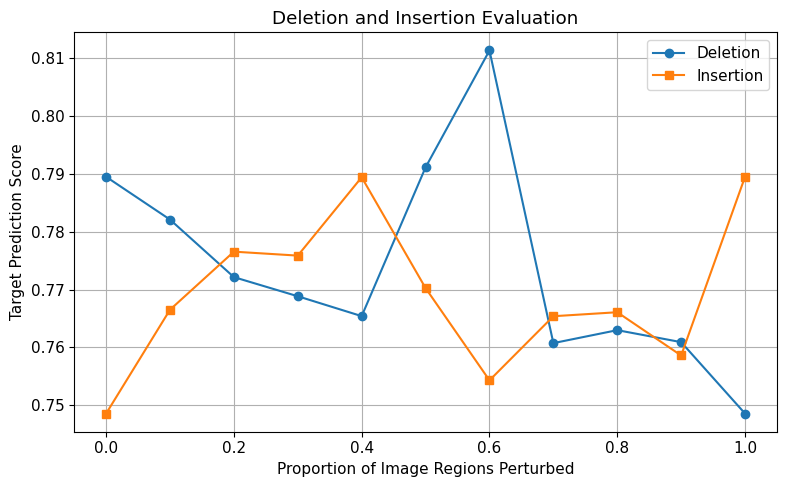

In [69]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    np.linspace(0, 1, len(deletion_scores)),
    deletion_scores,
    marker='o',
    label='Deletion'
)

ax.plot(
    np.linspace(0, 1, len(insertion_scores)),
    insertion_scores,
    marker='s',
    label='Insertion'
)

ax.set_xlabel("Proportion of Image Regions Perturbed")
ax.set_ylabel("Target Prediction Score")
ax.set_title("Deletion and Insertion Evaluation")
ax.legend()
ax.grid(True)

plt.tight_layout()
display(fig)
plt.close(fig)

select another sample

In [71]:
polyp_images = []

for label_path in Path(TEST_LABEL_DIR).glob("*.txt"):
    with open(label_path, "r") as file:
        for line in file:
            values = line.strip().split()

            if values and int(values[0]) == 0:
                polyp_images.append(label_path.stem + ".jpg")
                break

print("Number of images containing polyps:", len(polyp_images))
print("First 10 polyp images:", polyp_images[:10])

Number of images containing polyps: 150
First 10 polyp images: ['cju7atnm31if40817pqclnjer.jpg', 'cju5v8pgplg6k0755rvi2t63h.jpg', 'cju8djdqztu6408506pzhlo18.jpg', 'cju87q6yoneim0871dl4phvkd.jpg', 'cju5y4hgqmk0i08180rjhbwvp.jpg', 'cju7arvfe1ldu0850erdmphgj.jpg', 'cju17r8il13910799dr2wme2e.jpg', 'cju8bljw9rqk20801kr54akrl.jpg', 'cju42dwedlmk60871jbgu4ehi.jpg', 'cju3x5u2tiihx0818914gzxy1.jpg']


select the first image from this list

In [78]:
selected_image_name = polyp_images[45]

selected_image_path = os.path.join(
    TEST_IMAGE_DIR,
    selected_image_name
)

selected_label_path = os.path.join(
    TEST_LABEL_DIR,
    Path(selected_image_name).stem + ".txt"
)

print("Selected image:", selected_image_name)
print("Image exists:", os.path.exists(selected_image_path))
print("Label exists:", os.path.exists(selected_label_path))

Selected image: cju2lz8vqktne0993fuym6drw.jpg
Image exists: True
Label exists: True


load and display the original image.

In [79]:
original_image = cv2.imread(selected_image_path)
original_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 6))
plt.imshow(original_image)
plt.title("Second Sample: Polyp Image (Index 45)")
plt.axis("off")
plt.show()

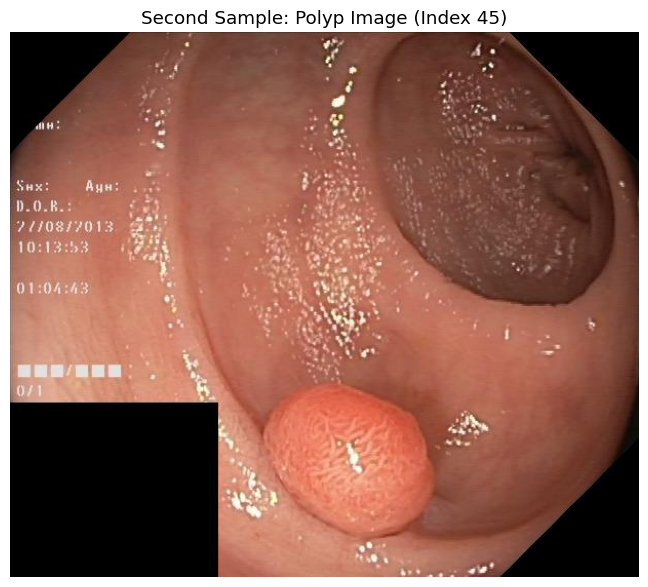

In [80]:
from IPython.display import display

fig, ax = plt.subplots(figsize=(8, 6))

ax.imshow(original_image)
ax.set_title("Second Sample: Polyp Image (Index 45)")
ax.axis("off")

plt.tight_layout()
display(fig)
plt.close(fig)

load its ground-truth bounding boxes and class labels.

In [81]:
image_height, image_width = original_image.shape[:2]

gt_boxes, gt_classes = read_yolo_labels(
    selected_label_path,
    image_width,
    image_height
)

print("Image dimensions:", original_image.shape)
print("Ground-truth boxes:", gt_boxes)
print("Ground-truth class IDs:", gt_classes)
print("Ground-truth classes:", [CLASS_NAMES[c] for c in gt_classes])

Image dimensions: (531, 613, 3)
Ground-truth boxes: [[247, 340, 414, 490]]
Ground-truth class IDs: [0]
Ground-truth classes: ['polyps']


preprocess this image for YOLOv5 and perform a forward pass.

In [82]:
# Preprocess the second sample
img = letterbox(original_image, new_shape=320)[0]
img = img.transpose((2, 0, 1))
img = np.ascontiguousarray(img)

input_tensor = torch.from_numpy(img).to(device).float() / 255.0
input_tensor = input_tensor.unsqueeze(0).requires_grad_(True)

# Clear previous Grad-CAM results
activations.clear()
gradients.clear()

# Forward pass
model.eval()
output = model(input_tensor)

print("Input tensor shape:", input_tensor.shape)
print("Model output shape:", output[0].shape)
print("Feature map shape:", activations[-1].shape)

Input tensor shape: torch.Size([1, 3, 288, 320])
Model output shape: torch.Size([1, 5670, 13])
Feature map shape: torch.Size([1, 512, 9, 10])


In [83]:
predictions = output[0][0]

polyp_scores = (
    predictions[:, 4] * predictions[:, 5]
)

best_index = polyp_scores.argmax()

selected_index = best_index.item()
selected_class = 0

target_score = polyp_scores[best_index]

print("Selected candidate index:", selected_index)
print("Selected class:", CLASS_NAMES[selected_class])
print("Target score:", target_score.item())
print("Gradient enabled:", target_score.requires_grad)

Selected candidate index: 5555
Selected class: polyps
Target score: 0.9660331010818481
Gradient enabled: True


generate the Grad-CAM heatmap for this polyp prediction.

In [84]:
model.zero_grad()
target_score.backward()

feature_maps = activations[-1]
grads = gradients[-1]

weights = grads.mean(dim=(2, 3), keepdim=True)

cam = (weights * feature_maps).sum(dim=1, keepdim=True)
cam = torch.relu(cam)
cam = cam.squeeze()

cam = cam - cam.min()
cam = cam / (cam.max() + 1e-8)

cam = cam.detach().cpu().numpy()

print("Grad-CAM shape:", cam.shape)
print("Minimum:", cam.min())
print("Maximum:", cam.max())

Grad-CAM shape: (9, 10)
Minimum: 0.0
Maximum: 0.9999957


generate the overlay.

In [85]:
height, width = original_image.shape[:2]

cam_resized = cv2.resize(
    cam,
    (width, height),
    interpolation=cv2.INTER_LINEAR
)

cam_uint8 = np.uint8(255 * cam_resized)

heatmap_color = cv2.applyColorMap(
    cam_uint8,
    cv2.COLORMAP_JET
)

heatmap_color = cv2.cvtColor(
    heatmap_color,
    cv2.COLOR_BGR2RGB
)

overlay = cv2.addWeighted(
    original_image, 0.6,
    heatmap_color, 0.4,
    0
)

print("Original image:", original_image.shape)
print("Resized CAM:", cam_resized.shape)
print("Overlay:", overlay.shape)

Original image: (531, 613, 3)
Resized CAM: (531, 613)
Overlay: (531, 613, 3)


four-panel visualization

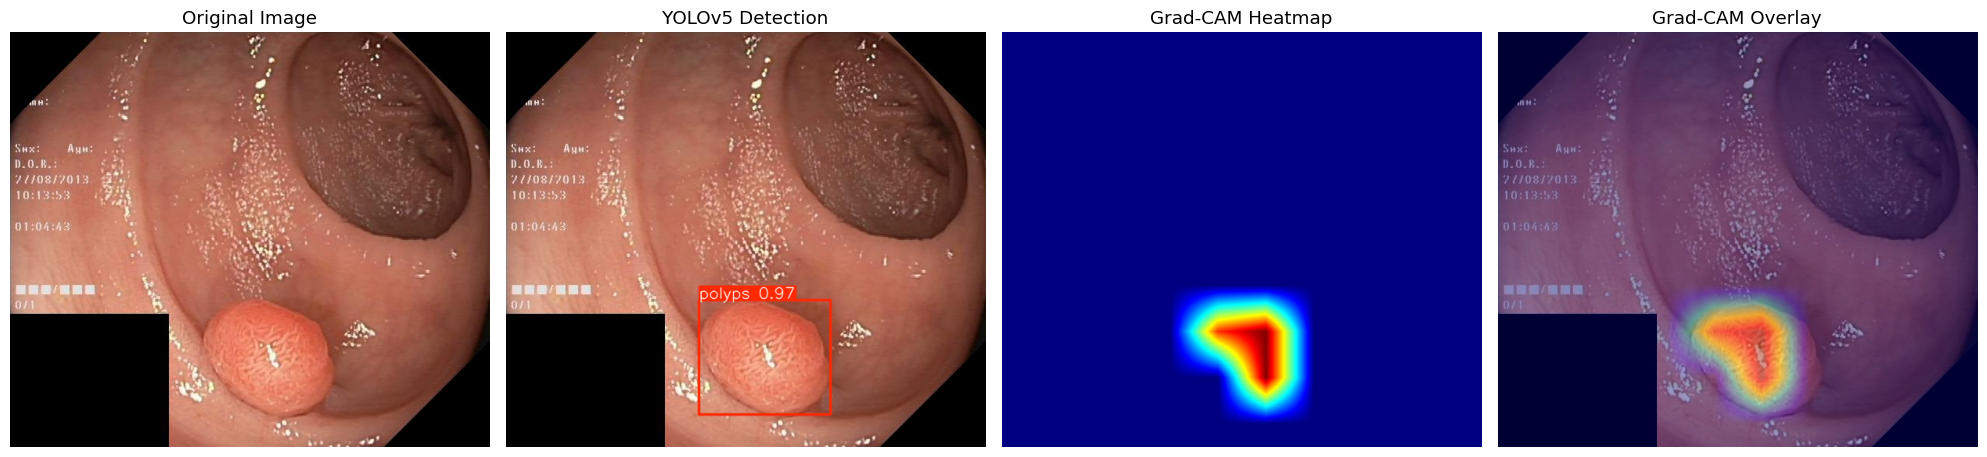

Number of YOLOv5 detections: 1


In [86]:
from utils.general import non_max_suppression, scale_boxes
from utils.plots import Annotator, colors

# Generate YOLOv5 detections
detections = non_max_suppression(
    output[0],
    conf_thres=0.25,
    iou_thres=0.45
)[0]

detection_image = original_image.copy()

if len(detections):
    detections[:, :4] = scale_boxes(
        input_tensor.shape[2:],
        detections[:, :4],
        original_image.shape
    ).round()

    annotator = Annotator(detection_image)

    for *xyxy, conf, cls in detections:
        class_id = int(cls)
        label = f'{CLASS_NAMES[class_id]} {conf:.2f}'

        annotator.box_label(
            xyxy,
            label,
            color=colors(class_id, True)
        )

    detection_image = annotator.result()

# Four-panel visualization
fig, axes = plt.subplots(1, 4, figsize=(20, 6))

images = [
    original_image,
    detection_image,
    heatmap_color,
    overlay
]

titles = [
    "Original Image",
    "YOLOv5 Detection",
    "Grad-CAM Heatmap",
    "Grad-CAM Overlay"
]

for ax, image, title in zip(axes, images, titles):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
display(fig)
plt.close(fig)

print("Number of YOLOv5 detections:", len(detections))

update the Energy Inside Box function

In [87]:
def calculate_energy_inside_box(cam, boxes, image_shape):
    total_energy = np.sum(cam)

    if total_energy <= 1e-8:
        return np.nan

    image_height, image_width = image_shape[:2]
    cam_height, cam_width = cam.shape

    combined_mask = np.zeros(
        (cam_height, cam_width),
        dtype=bool
    )

    for x1, y1, x2, y2 in boxes:
        cam_x1 = int(x1 * cam_width / image_width)
        cam_y1 = int(y1 * cam_height / image_height)
        cam_x2 = int(np.ceil(x2 * cam_width / image_width))
        cam_y2 = int(np.ceil(y2 * cam_height / image_height))

        combined_mask[cam_y1:cam_y2, cam_x1:cam_x2] = True

    inside_energy = np.sum(cam[combined_mask])

    return float(inside_energy / total_energy)


energy_inside_box = calculate_energy_inside_box(
    cam, gt_boxes, original_image.shape
)

print(f"Energy Inside Box: {energy_inside_box:.6f}")

Energy Inside Box: 1.000000


Pointing Game Accuracy.

In [88]:
def calculate_pointing_game(cam, boxes, image_shape):
    if cam.size == 0 or np.max(cam) <= 0:
        return np.nan

    max_y, max_x = np.unravel_index(
        np.argmax(cam), cam.shape
    )

    image_height, image_width = image_shape[:2]
    cam_height, cam_width = cam.shape

    for x1, y1, x2, y2 in boxes:
        cam_x1 = x1 * cam_width / image_width
        cam_y1 = y1 * cam_height / image_height
        cam_x2 = x2 * cam_width / image_width
        cam_y2 = y2 * cam_height / image_height

        if (cam_x1 <= max_x < cam_x2 and
            cam_y1 <= max_y < cam_y2):
            return 1

    return 0


pointing_game = calculate_pointing_game(
    cam, gt_boxes, original_image.shape
)

print("Pointing Game Accuracy:", pointing_game)

Pointing Game Accuracy: 1


# Deletion and Insertion evaluation for this second sample.

In [89]:
TARGET_INDEX = selected_index
TARGET_CLASS = 0

print("Target index:", TARGET_INDEX)
print("Target class:", CLASS_NAMES[TARGET_CLASS])
print("Original target score:", target_score.item())

Target index: 5555
Target class: polyps
Original target score: 0.9660331010818481


create the blurred baseline

In [90]:
blurred_image = cv2.GaussianBlur(
    original_image,
    (BLUR_KERNEL_SIZE, BLUR_KERNEL_SIZE),
    0
)

print("Blurred image shape:", blurred_image.shape)
print("Blurred baseline created:", blurred_image is not None)

Blurred image shape: (531, 613, 3)
Blurred baseline created: True


calculate the Grad-CAM importance ranking

In [91]:
cam_height, cam_width = cam.shape

y_regions = np.array_split(
    np.arange(original_image.shape[0]), cam_height
)

x_regions = np.array_split(
    np.arange(original_image.shape[1]), cam_width
)

region_scores = np.zeros((cam_height, cam_width))

for i, y in enumerate(y_regions):
    for j, x in enumerate(x_regions):
        region_scores[i, j] = np.mean(cam[i, j])

ranked_regions = np.argsort(
    region_scores.flatten()
)[::-1]

print("CAM grid:", cam.shape)
print("Total regions:", len(ranked_regions))
print("Top 10 region indices:", ranked_regions[:10])
print("Top 10 importance scores:",
      region_scores.flatten()[ranked_regions[:10]])

CAM grid: (9, 10)
Total regions: 90
Top 10 region indices: [65 75 64 87 85 84 83 86 89 88]
Top 10 importance scores: [          1     0.99984     0.82718           0           0           0           0           0           0           0]


Run Deletion evaluation for the second sample.

In [92]:
deletion_scores_sample2 = [get_target_score(original_image)]

for step in range(1, NUM_STEPS + 1):
    number_to_remove = int(
        np.ceil(step * len(ranked_regions) / NUM_STEPS)
    )

    selected_regions = ranked_regions[:number_to_remove]

    deleted_image = replace_regions(
        original_image,
        blurred_image,
        selected_regions
    )

    score = get_target_score(deleted_image)
    deletion_scores_sample2.append(score)

print("Deletion evaluation completed.")
print("Number of scores:", len(deletion_scores_sample2))
print("Deletion scores:", deletion_scores_sample2)

Deletion evaluation completed.
Number of scores: 11
Deletion scores: [0.9660331010818481, 0.9619848132133484, 0.9603884220123291, 0.9647742509841919, 0.9666925072669983, 0.9653545022010803, 0.9653917551040649, 0.965643584728241, 0.9656640887260437, 0.9665714502334595, 0.9663841724395752]


calculate its Deletion AUC.

In [93]:
deletion_x_sample2 = np.linspace(
    0, 1, len(deletion_scores_sample2)
)

deletion_auc_sample2 = np.trapezoid(
    deletion_scores_sample2,
    deletion_x_sample2
)

print(f"Sample 2 Deletion AUC: {deletion_auc_sample2:.6f}")

Sample 2 Deletion AUC: 0.964867


Insertion evaluation

In [94]:
insertion_scores_sample2 = [get_target_score(blurred_image)]

for step in range(1, NUM_STEPS + 1):
    number_to_restore = int(
        np.ceil(step * len(ranked_regions) / NUM_STEPS)
    )

    selected_regions = ranked_regions[:number_to_restore]

    inserted_image = replace_regions(
        blurred_image,
        original_image,
        selected_regions
    )

    score = get_target_score(inserted_image)
    insertion_scores_sample2.append(score)

print("Insertion evaluation completed.")
print("Number of scores:", len(insertion_scores_sample2))
print("Insertion scores:", insertion_scores_sample2)

Insertion evaluation completed.
Number of scores: 11
Insertion scores: [0.9663841724395752, 0.9636416435241699, 0.9656500220298767, 0.9647311568260193, 0.9643266797065735, 0.9654999375343323, 0.9660340547561646, 0.9659937620162964, 0.9659724831581116, 0.96614009141922, 0.9660331010818481]


calculate the Insertion AUC.

In [95]:
insertion_x_sample2 = np.linspace(
    0, 1, len(insertion_scores_sample2)
)

insertion_auc_sample2 = np.trapezoid(
    insertion_scores_sample2,
    insertion_x_sample2
)

print(f"Sample 2 Insertion AUC: {insertion_auc_sample2:.6f}")

Sample 2 Insertion AUC: 0.965420


Save the updated results

In [96]:
results = [
    {
        "Sample": 1,
        "Image": "0013240d-bb50-4886-a616-e1995eb1a163.jpg",
        "Class": "inadequate",
        "Energy_Inside_Box": 1.0,
        "Pointing_Game": 1,
        "Deletion_AUC": deletion_auc,
        "Insertion_AUC": insertion_auc
    },
    {
        "Sample": 2,
        "Image": selected_image_name,
        "Class": "polyps",
        "Energy_Inside_Box": energy_inside_box,
        "Pointing_Game": pointing_game,
        "Deletion_AUC": deletion_auc_sample2,
        "Insertion_AUC": insertion_auc_sample2
    }
]

results_df = pd.DataFrame(results)

save_path = os.path.join(
    RESULTS_DIR,
    "XAI_Evaluation_Summary.csv"
)

results_df.to_csv(save_path, index=False)

display(results_df)
print("Saved:", save_path)

,Sample,Image,Class,Energy_Inside_Box,Pointing_Game,Deletion_AUC,Insertion_AUC
0,1,0013240d-bb50-4886-a616-e1995eb1a163.jpg,inadequate,1.0,1,0.774467,0.769204
1,2,cju2lz8vqktne0993fuym6drw.jpg,polyps,1.0,1,0.964867,0.965420


Saved: /content/XAI_Project/Evaluation_Results/XAI_Evaluation_Summary.csv


In [99]:
from google.colab import files

files.download(
    "/content/XAI_Project/Evaluation_Results/XAI_Evaluation_Summary.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

visualize the Deletion and Insertion curves for Sample 2

In [100]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(0, 1, len(deletion_scores_sample2))

plt.figure(figsize=(8, 5))

plt.plot(
    x, deletion_scores_sample2,
    marker='o', label='Deletion'
)

plt.plot(
    x, insertion_scores_sample2,
    marker='s', label='Insertion'
)

plt.xlabel("Proportion of Image Regions Perturbed")
plt.ylabel("YOLO Target Prediction Score")
plt.title("Deletion and Insertion Curves – Sample 2")
plt.legend()
plt.grid(True)
plt.show()

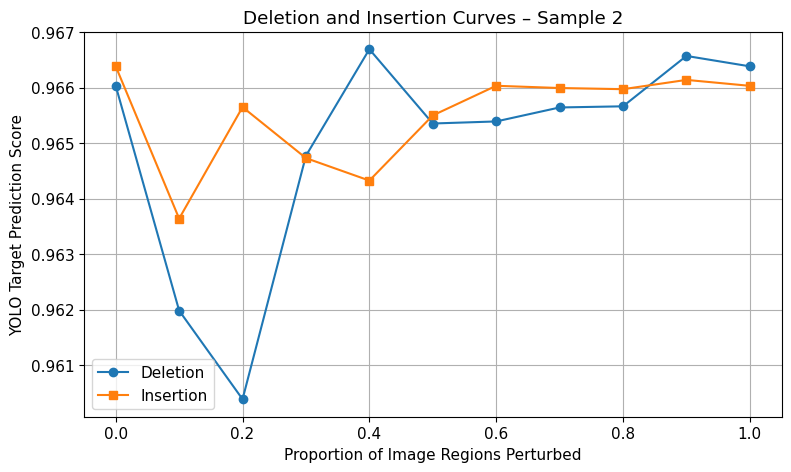

In [101]:
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(0, 1, len(deletion_scores_sample2))

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(x, deletion_scores_sample2, marker='o', label='Deletion')
ax.plot(x, insertion_scores_sample2, marker='s', label='Insertion')

ax.set_xlabel("Proportion of Image Regions Perturbed")
ax.set_ylabel("YOLO Target Prediction Score")
ax.set_title("Deletion and Insertion Curves – Sample 2")
ax.legend()
ax.grid(True)

display(fig)
plt.close(fig)

how much the YOLO prediction score changed during Deletion and Insertion for Sample 2.

In [102]:
print("Sample 2 – Perturbation Analysis")
print("--------------------------------")

print(
    "Original prediction score:",
    round(deletion_scores_sample2[0], 6)
)

print(
    "Deletion score range:",
    round(min(deletion_scores_sample2), 6),
    "to",
    round(max(deletion_scores_sample2), 6)
)

print(
    "Insertion score range:",
    round(min(insertion_scores_sample2), 6),
    "to",
    round(max(insertion_scores_sample2), 6)
)

print(
    "Deletion score change:",
    round(
        max(deletion_scores_sample2) -
        min(deletion_scores_sample2), 6
    )
)

Sample 2 – Perturbation Analysis
--------------------------------
Original prediction score: 0.966033
Deletion score range: 0.960388 to 0.966693
Insertion score range: 0.963642 to 0.966384
Deletion score change: 0.006304


save it

In [103]:
import pandas as pd
from google.colab import files

steps = range(len(deletion_scores_sample2))

score_changes = pd.DataFrame({
    "Step": steps,
    "Proportion_Perturbed": [
        round(step / NUM_STEPS, 2) for step in steps
    ],
    "Deletion_Score": deletion_scores_sample2,
    "Insertion_Score": insertion_scores_sample2
})

score_path = os.path.join(
    RESULTS_DIR,
    "Sample_2_Prediction_Score_Changes.csv"
)

score_changes.to_csv(score_path, index=False)

display(score_changes)

files.download(score_path)

,Step,Proportion_Perturbed,Deletion_Score,Insertion_Score
0,0,0.0,0.966033,0.966384
1,1,0.1,0.961985,0.963642
2,2,0.2,0.960388,0.965650
3,3,0.3,0.964774,0.964731
4,4,0.4,0.966693,0.964327
5,5,0.5,0.965355,0.965500
6,6,0.6,0.965392,0.966034
7,7,0.7,0.965644,0.965994
8,8,0.8,0.965664,0.965972
9,9,0.9,0.966571,0.966140


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# full evaluation of all 1,200 test images
Check the dataset and class distribution


In [104]:
from collections import Counter

class_counts = Counter()

for label_path in label_files:
    boxes, class_ids = read_yolo_labels(
        label_path, 1, 1
    )
    class_counts.update(class_ids)

print("Total test images:", len(image_files))
print("Total label files:", len(label_files))
print("\nGround-truth object counts:")

for class_id, count in sorted(class_counts.items()):
    print(f"{CLASS_NAMES[class_id]}: {count}")

print("\nTotal annotated objects:", sum(class_counts.values()))

FileNotFoundError: [Errno 2] No such file or directory: '0013240d-bb50-4886-a616-e1995eb1a163.txt'

Correct the label file paths

In [105]:
label_files = sorted(
    Path(TEST_LABEL_DIR).glob("*.txt")
)

print("Number of label files:", len(label_files))
print("First label path:", label_files[0])
print("File exists:", label_files[0].exists())

Number of label files: 1200
First label path: /content/XAI_Project/test_dataset/test_label/0013240d-bb50-4886-a616-e1995eb1a163.txt
File exists: True


Count the ground-truth objects

In [106]:
from collections import Counter

class_counts = Counter()

for label_path in label_files:
    boxes, class_ids = read_yolo_labels(
        label_path, 1, 1
    )
    class_counts.update(class_ids)

print("Ground-truth object distribution")
print("--------------------------------")

for class_id, count in sorted(class_counts.items()):
    print(f"{CLASS_NAMES[class_id]}: {count}")

print("--------------------------------")
print("Total annotated objects:", sum(class_counts.values()))

Ground-truth object distribution
--------------------------------
polyps: 153
cecum: 159
inadequate: 146
normal: 147
impaction: 335
retroflexion: 154
UC: 140
hemorrhoid: 170
--------------------------------
Total annotated objects: 1404


Prepare the Grad-CAM hooks

In [107]:
# Remove previously registered hooks, if they exist
try:
    forward_handle.remove()
except NameError:
    pass

try:
    backward_handle.remove()
except NameError:
    pass

# Clear previously stored activations and gradients
activations.clear()
gradients.clear()

# Control when Grad-CAM information is collected
CAPTURE_CAM = True

def forward_hook(module, input, output):
    if CAPTURE_CAM:
        activations.append(output)

def backward_hook(module, grad_input, grad_output):
    if CAPTURE_CAM:
        gradients.append(grad_output[0])

# Register fresh hooks
forward_handle = target_layer.register_forward_hook(forward_hook)
backward_handle = target_layer.register_full_backward_hook(backward_hook)

print("Grad-CAM hooks prepared successfully.")
print("Forward hook registered:", forward_handle is not None)
print("Backward hook registered:", backward_handle is not None)
print("Activation storage:", len(activations))
print("Gradient storage:", len(gradients))

Grad-CAM hooks prepared successfully.
Forward hook registered: True
Backward hook registered: True
Activation storage: 0
Gradient storage: 0


Prevent memory accumulation during Deletion and Insertion

In [108]:
def get_target_score(image):
    global CAPTURE_CAM

    previous_capture_state = CAPTURE_CAM
    CAPTURE_CAM = False

    try:
        processed = letterbox(image, new_shape=320)[0]
        processed = processed.transpose((2, 0, 1))
        processed = np.ascontiguousarray(processed)

        tensor = torch.from_numpy(processed).to(device).float() / 255.0
        tensor = tensor.unsqueeze(0)

        with torch.no_grad():
            prediction = model(tensor)[0]

        score = (
            prediction[0, TARGET_INDEX, 4]
            * prediction[0, TARGET_INDEX, 5 + TARGET_CLASS]
        )

        return float(score.item())

    finally:
        CAPTURE_CAM = previous_capture_state

print("Prediction scoring function updated successfully.")

Prediction scoring function updated successfully.


Test Grad-CAM generation automatically

In [109]:
# Select the first test image
test_image_path = str(image_files[0])

# Load image
test_image = cv2.imread(test_image_path)
test_image = cv2.cvtColor(test_image, cv2.COLOR_BGR2RGB)

# Prepare model input
processed = letterbox(test_image, new_shape=320)[0]
processed = processed.transpose((2, 0, 1))
processed = np.ascontiguousarray(processed)

input_tensor = (
    torch.from_numpy(processed)
    .to(device)
    .float()
    .div(255.0)
    .unsqueeze(0)
)

input_tensor = input_tensor.detach().requires_grad_(True)

# Clear previous CAM information
activations.clear()
gradients.clear()

CAPTURE_CAM = True
model.zero_grad(set_to_none=True)

# Forward pass
output = model(input_tensor)[0]

# Select the strongest class prediction
predictions = output[0]
class_scores = predictions[:, 4:5] * predictions[:, 5:]
best_index = torch.argmax(class_scores)
candidate_index = best_index // NUM_CLASSES
class_index = best_index % NUM_CLASSES

target_score = class_scores.flatten()[best_index]
target_score.backward()

print("Image:", os.path.basename(test_image_path))
print("Selected class:", CLASS_NAMES[int(class_index.item())])
print("Target score:", round(target_score.item(), 6))
print("Activation shape:", tuple(activations[0].shape))
print("Gradient shape:", tuple(gradients[0].shape))

error: OpenCV(4.14.0) /io/opencv/modules/imgproc/src/color.cpp:199: error: (-215:Assertion failed) !_src.empty() in function 'cvtColor'


Check the image path

In [110]:
print("First image entry:", image_files[0])
print("Image directory:", TEST_IMAGE_DIR)

test_image_path = os.path.join(
    TEST_IMAGE_DIR,
    os.path.basename(str(image_files[0]))
)

print("Full image path:", test_image_path)
print("File exists:", os.path.exists(test_image_path))

First image entry: 0013240d-bb50-4886-a616-e1995eb1a163.jpg
Image directory: /content/XAI_Project/test_dataset/test_img
Full image path: /content/XAI_Project/test_dataset/test_img/0013240d-bb50-4886-a616-e1995eb1a163.jpg
File exists: True


Load the image

In [111]:
test_image_path = os.path.join(
    TEST_IMAGE_DIR,
    os.path.basename(str(image_files[0]))
)

test_image = cv2.imread(test_image_path)

if test_image is not None:
    test_image = cv2.cvtColor(
        test_image, cv2.COLOR_BGR2RGB
    )
    print("Image loaded successfully!")
    print("Image shape:", test_image.shape)
else:
    print("Image loading failed.")

Image loaded successfully!
Image shape: (531, 633, 3)


Verify Grad-CAM generation

In [112]:
# Prepare the image for YOLOv5
processed = letterbox(test_image, new_shape=320)[0]
processed = processed.transpose((2, 0, 1))
processed = np.ascontiguousarray(processed)

input_tensor = torch.from_numpy(processed).to(device).float() / 255.0
input_tensor = input_tensor.unsqueeze(0).requires_grad_(True)

# Clear previous information
activations.clear()
gradients.clear()

CAPTURE_CAM = True
model.zero_grad(set_to_none=True)

# Forward pass
output = model(input_tensor)[0]
predictions = output[0]

# Select the strongest class-candidate combination
class_scores = predictions[:, 4:5] * predictions[:, 5:]
best_index = torch.argmax(class_scores.flatten())

candidate_index = best_index // NUM_CLASSES
class_index = best_index % NUM_CLASSES

target_score = class_scores.flatten()[best_index]
target_score.backward()

print("Selected class:", CLASS_NAMES[int(class_index.item())])
print("Target score:", round(target_score.item(), 6))
print("Activation shape:", tuple(activations[0].shape))
print("Gradient shape:", tuple(gradients[0].shape))

Selected class: inadequate
Target score: 0.789507
Activation shape: (1, 512, 9, 10)
Gradient shape: (1, 512, 9, 10)


Create the automated evaluation function

automated evaluation function is available

In [122]:

def evaluate_one_image(image_path, label_path, num_steps=10):

    global CAPTURE_CAM

    # 1. Load image and annotations
    image = cv2.imread(str(image_path))
    if image is None:
        raise ValueError(f"Cannot load image: {image_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    h, w = image.shape[:2]

    boxes, class_ids = read_yolo_labels(label_path, w, h)

    if not boxes:
        return None

    # 2. Prepare model input
    processed = letterbox(image, new_shape=320)[0]
    processed = np.ascontiguousarray(
        processed.transpose((2, 0, 1))
    )

    input_tensor = (
        torch.from_numpy(processed)
        .to(device).float().div(255.0)
        .unsqueeze(0)
        .requires_grad_(True)
    )

    # 3. Generate Grad-CAM
    activations.clear()
    gradients.clear()

    CAPTURE_CAM = True
    model.zero_grad(set_to_none=True)

    output = model(input_tensor)[0]
    predictions = output[0]

    # Select the strongest candidate among annotated classes
    unique_classes = sorted(set(class_ids))

    class_scores = (
        predictions[:, 4:5] * predictions[:, 5:]
    )

    selected_scores = class_scores[:, unique_classes]
    best_position = torch.argmax(selected_scores.flatten())

    candidate_index = (
        best_position // len(unique_classes)
    )
    class_position = (
        best_position % len(unique_classes)
    )

    target_index = int(candidate_index.item())
    target_class = int(
        unique_classes[int(class_position.item())]
    )

    target_score = class_scores[
        target_index, target_class
    ]

    target_score.backward()

    if not activations or not gradients:
        raise RuntimeError(
            "Grad-CAM hooks did not capture data."
        )

    activation = activations[0].detach()
    gradient = gradients[0].detach()

    weights = gradient.mean(
        dim=(2, 3), keepdim=True
    )

    cam = torch.relu(
        (weights * activation).sum(dim=1)
    )[0].cpu().numpy()

    cam = cam / (cam.max() + 1e-8)

    # 4. Calculate class-specific localization metrics
    target_boxes = [
        box for box, class_id in zip(boxes, class_ids)
        if class_id == target_class
    ]

    energy = calculate_energy_inside_box(
        cam, target_boxes, image.shape
    )

    pointing = calculate_pointing_game(
        cam, target_boxes, image.shape
    )

    # 5. Prepare perturbation regions
    cam_h, cam_w = cam.shape

    y_edges = np.linspace(
        0, h, cam_h + 1, dtype=int
    )

    x_edges = np.linspace(
        0, w, cam_w + 1, dtype=int
    )

    ranked_regions = np.argsort(
        cam.flatten()
    )[::-1]

    blurred = cv2.GaussianBlur(
        image,
        (BLUR_KERNEL_SIZE, BLUR_KERNEL_SIZE),
        0
    )

    def perturb(source, replacement, indices):

        result = source.copy()

        for index in indices:

            row, col = divmod(
                int(index), cam_w
            )

            result[
                y_edges[row]:y_edges[row + 1],
                x_edges[col]:x_edges[col + 1]
            ] = replacement[
                y_edges[row]:y_edges[row + 1],
                x_edges[col]:x_edges[col + 1]
            ]

        return result

    # 6. Score the same raw YOLO candidate
    def score_candidate(img):

        processed_img = letterbox(
            img, new_shape=320
        )[0]

        processed_img = np.ascontiguousarray(
            processed_img.transpose((2, 0, 1))
        )

        tensor = (
            torch.from_numpy(processed_img)
            .to(device).float().div(255.0)
            .unsqueeze(0)
        )

        with torch.no_grad():
            pred = model(tensor)[0]

        return float(
            (
                pred[0, target_index, 4]
                * pred[0, target_index, 5 + target_class]
            ).item()
        )

    # 7. Deletion
    CAPTURE_CAM = False

    deletion_scores = [
        score_candidate(image)
    ]

    for step in range(1, num_steps + 1):

        count = int(
            np.ceil(
                step * len(ranked_regions) / num_steps
            )
        )

        deleted = perturb(
            image,
            blurred,
            ranked_regions[:count]
        )

        deletion_scores.append(
            score_candidate(deleted)
        )

    # 8. Insertion
    insertion_scores = [
        score_candidate(blurred)
    ]

    for step in range(1, num_steps + 1):

        count = int(
            np.ceil(
                step * len(ranked_regions) / num_steps
            )
        )

        inserted = perturb(
            blurred,
            image,
            ranked_regions[:count]
        )

        insertion_scores.append(
            score_candidate(inserted)
        )

    x = np.linspace(
        0, 1, num_steps + 1
    )

    deletion_auc = float(
        np.trapezoid(deletion_scores, x)
    )

    insertion_auc = float(
        np.trapezoid(insertion_scores, x)
    )

    # 9. Clear stored tensors
    CAPTURE_CAM = False
    activations.clear()
    gradients.clear()

    return {
        "Image": os.path.basename(str(image_path)),
        "Target_Class": CLASS_NAMES[target_class],
        "Target_Index": target_index,
        "Original_Score": float(target_score.item()),
        "Energy_Inside_Box": energy,
        "Pointing_Game": pointing,
        "Deletion_AUC": deletion_auc,
        "Insertion_AUC": insertion_auc,
        "Deletion_Scores": deletion_scores,
        "Insertion_Scores": insertion_scores
    }


In [114]:
print(evaluate_one_image)

<function evaluate_one_image at 0x789733e2e160>


# Prepare all 1,200 image-label pairs

In [115]:
# Create a dictionary of label files using their filenames
label_map = {
    Path(path).stem: Path(path)
    for path in label_files
}

# Match every image with its corresponding label
evaluation_pairs = []

for image_name in image_files:
    image_path = Path(TEST_IMAGE_DIR) / Path(image_name).name
    label_path = label_map.get(image_path.stem)

    if label_path is not None and image_path.exists():
        evaluation_pairs.append((image_path, label_path))

print("Total image-label pairs:", len(evaluation_pairs))
print("Expected:", 1200)
print("Unmatched images:", 1200 - len(evaluation_pairs))

print("\nFirst matched pair:")
print("Image:", evaluation_pairs[0][0])
print("Label:", evaluation_pairs[0][1])

Total image-label pairs: 1200
Expected: 1200
Unmatched images: 0

First matched pair:
Image: /content/XAI_Project/test_dataset/test_img/0013240d-bb50-4886-a616-e1995eb1a163.jpg
Label: /content/XAI_Project/test_dataset/test_label/0013240d-bb50-4886-a616-e1995eb1a163.txt


In [123]:
test_result = evaluate_one_image(
    evaluation_pairs[0][0],
    evaluation_pairs[0][1]
)

print(test_result)

{'Image': '0013240d-bb50-4886-a616-e1995eb1a163.jpg', 'Target_Class': 'inadequate', 'Target_Index': 5426, 'Original_Score': 0.7895070314407349, 'Energy_Inside_Box': 1.0, 'Pointing_Game': 1, 'Deletion_AUC': 0.7722457975149155, 'Insertion_AUC': 0.7690080612897874, 'Deletion_Scores': [0.7895070314407349, 0.7794777154922485, 0.7689329981803894, 0.7665683627128601, 0.7616006135940552, 0.7869632244110107, 0.8086748719215393, 0.7579776048660278, 0.7618604302406311, 0.7613706588745117, 0.7485559582710266], 'Insertion_Scores': [0.7485559582710266, 0.7655638456344604, 0.7757754921913147, 0.7748851776123047, 0.789212167263031, 0.7706174850463867, 0.754641056060791, 0.7655831575393677, 0.766133725643158, 0.758637011051178, 0.7895070314407349]}


# Run the complete evaluation

In [ ]:

import os
import json
import pandas as pd
from tqdm.auto import tqdm

# Create output directory
os.makedirs(RESULTS_DIR, exist_ok=True)

# Store successful results and errors
all_results = []
evaluation_errors = []
skipped_images = 0

total_images = len(evaluation_pairs)

print(f"Starting evaluation of {total_images} images...")

for index, (image_path, label_path) in enumerate(
    tqdm(evaluation_pairs, desc="Evaluating images"),
    start=1
):

    try:
        result = evaluate_one_image(
            image_path,
            label_path,
            num_steps=10
        )

        if result is None:
            skipped_images += 1

        else:
            # Convert score lists to JSON strings for CSV storage
            result["Deletion_Scores"] = json.dumps(
                result["Deletion_Scores"]
            )

            result["Insertion_Scores"] = json.dumps(
                result["Insertion_Scores"]
            )

            all_results.append(result)

    except Exception as e:

        evaluation_errors.append({
            "Image": os.path.basename(str(image_path)),
            "Error": str(e)
        })

    # Save progress every 25 images
    if index % 25 == 0 or index == total_images:

        pd.DataFrame(all_results).to_csv(
            os.path.join(
                RESULTS_DIR,
                "XAI_Evaluation_1200_Images.csv"
            ),
            index=False
        )

        pd.DataFrame(evaluation_errors).to_csv(
            os.path.join(
                RESULTS_DIR,
                "XAI_Evaluation_Errors.csv"
            ),
            index=False
        )

        print(
            f"\nProgress: {index}/{total_images}"
            f" | Successful: {len(all_results)}"
            f" | Skipped: {skipped_images}"
            f" | Errors: {len(evaluation_errors)}"
        )

print("\nEVALUATION COMPLETED")
print("--------------------")
print("Total images:", total_images)
print("Successful evaluations:", len(all_results))
print("Skipped images:", skipped_images)
print("Errors:", len(evaluation_errors))

print("\nResults saved in:", RESULTS_DIR)


Starting evaluation of 1200 images...


Evaluating images:   0%|          | 0/1200 [00:00<?, ?it/s]


Progress: 25/1200 | Successful: 25 | Skipped: 0 | Errors: 0

Progress: 50/1200 | Successful: 50 | Skipped: 0 | Errors: 0

Progress: 75/1200 | Successful: 75 | Skipped: 0 | Errors: 0

Progress: 100/1200 | Successful: 100 | Skipped: 0 | Errors: 0

Progress: 125/1200 | Successful: 125 | Skipped: 0 | Errors: 0

Progress: 150/1200 | Successful: 150 | Skipped: 0 | Errors: 0

Progress: 175/1200 | Successful: 175 | Skipped: 0 | Errors: 0

Progress: 200/1200 | Successful: 200 | Skipped: 0 | Errors: 0

Progress: 225/1200 | Successful: 225 | Skipped: 0 | Errors: 0

Progress: 250/1200 | Successful: 250 | Skipped: 0 | Errors: 0

Progress: 275/1200 | Successful: 275 | Skipped: 0 | Errors: 0

Progress: 300/1200 | Successful: 300 | Skipped: 0 | Errors: 0

Progress: 325/1200 | Successful: 325 | Skipped: 0 | Errors: 0

Progress: 350/1200 | Successful: 350 | Skipped: 0 | Errors: 0

Progress: 375/1200 | Successful: 375 | Skipped: 0 | Errors: 0

Progress: 400/1200 | Successful: 400 | Skipped: 0 | Errors: 

In [125]:
import os
import pandas as pd

csv_path = os.path.join(
    RESULTS_DIR,
    "XAI_Evaluation_1200_Images.csv"
)

if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    print("Saved evaluation results:", len(df))
    print("File size:", os.path.getsize(csv_path), "bytes")
else:
    print("Evaluation CSV file not found.")

Saved evaluation results: 1199
File size: 667425 bytes


In [126]:

import os
import pandas as pd

csv_path = os.path.join(
    RESULTS_DIR,
    "XAI_Evaluation_1200_Images.csv"
)

df = pd.read_csv(csv_path)

saved_images = set(df["Image"].astype(str))

expected_images = {
    image_path.name
    for image_path, label_path in evaluation_pairs
}

missing_images = sorted(expected_images - saved_images)
duplicate_count = int(df["Image"].duplicated().sum())

print("Saved rows:", len(df))
print("Unique images saved:", len(saved_images))
print("Duplicate rows:", duplicate_count)
print("Missing images:", len(missing_images))
print("Missing image names:", missing_images)

if os.path.exists(os.path.join(RESULTS_DIR, "XAI_Evaluation_Errors.csv")):
    errors = pd.read_csv(
        os.path.join(RESULTS_DIR, "XAI_Evaluation_Errors.csv")
    )
    print("Recorded errors:", len(errors))


Saved rows: 1199
Unique images saved: 1199
Duplicate rows: 0
Missing images: 1
Missing image names: ['retro_24_3410.jpg']


EmptyDataError: No columns to parse from file

In [127]:
missing_name = "retro_24_3410.jpg"

missing_pair = next(
    (
        (img, lbl)
        for img, lbl in evaluation_pairs
        if img.name == missing_name
    ),
    None
)

if missing_pair is not None:
    result = evaluate_one_image(
        missing_pair[0],
        missing_pair[1],
        num_steps=10
    )

    if result is not None:
        print("Missing image evaluated successfully:")
        print(result)
    else:
        print("This image has no annotations.")
else:
    print("Image-label pair not found.")

This image has no annotations.


In [128]:
missing_label = next(
    lbl for img, lbl in evaluation_pairs
    if img.name == "retro_24_3410.jpg"
)

print("Label file:", missing_label)
print("File size:", os.path.getsize(missing_label), "bytes")

with open(missing_label, "r") as f:
    print("Label contents:", repr(f.read()))

Label file: /content/XAI_Project/test_dataset/test_label/retro_24_3410.txt
File size: 0 bytes
Label contents: ''


# Calculate the overall XAI metrics

In [130]:
import pandas as pd
import numpy as np
import os

csv_path = os.path.join(
    RESULTS_DIR,
    "XAI_Evaluation_1200_Images.csv"
)

df = pd.read_csv(csv_path)

metrics = [
    "Energy_Inside_Box",
    "Pointing_Game",
    "Deletion_AUC",
    "Insertion_AUC"
]

summary = df[metrics].agg(["mean", "std", "min", "max"]).T

summary.columns = [
    "Mean", "Standard_Deviation", "Minimum", "Maximum"
]

display(summary.round(4))

,Mean,Standard_Deviation,Minimum,Maximum
Energy_Inside_Box,0.9934,0.0635,0.0000,1.0000
Pointing_Game,0.9790,0.1434,0.0000,1.0000
Deletion_AUC,0.8331,0.1910,0.0001,0.9947
Insertion_AUC,0.8491,0.1868,0.0013,0.9949


In [131]:
from google.colab import files

files.download(
    "/content/XAI_Project/Evaluation_Results/XAI_Evaluation_1200_Images.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [132]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/XAI_Evaluation_Backup",
    "zip",
    RESULTS_DIR
)

files.download("/content/XAI_Evaluation_Backup.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [133]:
import os

for root, dirs, files_list in os.walk(RESULTS_DIR):
    print("\nFolder:", root)
    for file in files_list:
        print("  -", file)


Folder: /content/XAI_Project/Evaluation_Results
  - XAI_Evaluation_1200_Images.csv
  - XAI_Evaluation_Summary.csv
  - XAI_Evaluation_Errors.csv
  - 0013240d-bb50-4886-a616-e1995eb1a163_four_panel.png
  - Sample_2_Prediction_Score_Changes.csv
  - 0013240d-bb50-4886-a616-e1995eb1a163_gradcam.npy

Folder: /content/XAI_Project/Evaluation_Results/Four_Panel_Figures

Folder: /content/XAI_Project/Evaluation_Results/GradCAM_Heatmaps

Folder: /content/XAI_Project/Evaluation_Results/Metrics


In [134]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load evaluation results
csv_path = os.path.join(
    RESULTS_DIR,
    "XAI_Evaluation_1200_Images.csv"
)

df = pd.read_csv(csv_path)

# Metrics
metrics = [
    "Energy_Inside_Box",
    "Pointing_Game",
    "Deletion_AUC",
    "Insertion_AUC"
]

# Ensure numeric values
df[metrics] = df[metrics].apply(
    pd.to_numeric, errors="coerce"
)

# Create graph output directory
GRAPH_DIR = os.path.join(
    RESULTS_DIR, "Metric_Graphs"
)

os.makedirs(GRAPH_DIR, exist_ok=True)


# =====================================
# GRAPH 1: Overall metric distributions
# =====================================

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, metric in zip(axes.flat, metrics):

    values = df[metric].dropna()

    ax.hist(values, bins=25, edgecolor="black")

    ax.set_title(metric.replace("_", " "))
    ax.set_xlabel("Metric value")
    ax.set_ylabel("Number of images")
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(
    "Distribution of XAI Evaluation Metrics",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "Overall_XAI_Metric_Distributions.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# =====================================
# GRAPH 2: Class-wise metric comparison
# =====================================

class_means = df.groupby("Target_Class")[metrics].mean()

class_order = [
    "polyps",
    "cecum",
    "inadequate",
    "normal",
    "impaction",
    "retroflexion",
    "UC",
    "hemorrhoid"
]

class_means = class_means.reindex(class_order)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, metric in zip(axes.flat, metrics):

    ax.bar(
        class_means.index,
        class_means[metric],
        yerr=df.groupby("Target_Class")[metric]
            .std().reindex(class_order),
        capsize=4,
        edgecolor="black"
    )

    ax.set_title(metric.replace("_", " "))
    ax.set_ylabel("Mean value")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(
    "Class-wise Comparison of XAI Metrics",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "Classwise_XAI_Metric_Comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Both graphs generated successfully.")
print("Saved in:", GRAPH_DIR)


Both graphs generated successfully.
Saved in: /content/XAI_Project/Evaluation_Results/Metric_Graphs


In [135]:
from google.colab import files
import shutil

shutil.make_archive(
    "/content/XAI_Metric_Graphs",
    "zip",
    GRAPH_DIR
)

files.download("/content/XAI_Metric_Graphs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Generate the dataset-level deletion and insertion curves

In [136]:

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the existing evaluation results
csv_path = os.path.join(
    RESULTS_DIR,
    "XAI_Evaluation_1200_Images.csv"
)

df = pd.read_csv(csv_path)

# Convert stored score strings into numerical arrays
deletion_data = np.array([
    json.loads(scores)
    for scores in df["Deletion_Scores"].dropna()
])

insertion_data = np.array([
    json.loads(scores)
    for scores in df["Insertion_Scores"].dropna()
])

print("Images with deletion scores:", len(deletion_data))
print("Images with insertion scores:", len(insertion_data))

# Calculate mean and standard deviation at each step
deletion_mean = np.mean(deletion_data, axis=0)
deletion_std = np.std(deletion_data, axis=0)

insertion_mean = np.mean(insertion_data, axis=0)
insertion_std = np.std(insertion_data, axis=0)

# Percentage of image regions perturbed
steps = np.linspace(0, 100, deletion_data.shape[1])

# Create output directory
CURVE_DIR = os.path.join(
    RESULTS_DIR,
    "Deletion_Insertion_Curves"
)

os.makedirs(CURVE_DIR, exist_ok=True)

# Plot both curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Deletion curve
axes[0].plot(
    steps,
    deletion_mean,
    linewidth=2,
    label="Mean deletion score"
)

axes[0].fill_between(
    steps,
    deletion_mean - deletion_std,
    deletion_mean + deletion_std,
    alpha=0.2,
    label="±1 SD"
)

axes[0].set_title("Deletion Curve")
axes[0].set_xlabel("Percentage of regions removed (%)")
axes[0].set_ylabel("Mean prediction confidence")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Insertion curve
axes[1].plot(
    steps,
    insertion_mean,
    linewidth=2,
    label="Mean insertion score"
)

axes[1].fill_between(
    steps,
    insertion_mean - insertion_std,
    insertion_mean + insertion_std,
    alpha=0.2,
    label="±1 SD"
)

axes[1].set_title("Insertion Curve")
axes[1].set_xlabel("Percentage of regions restored (%)")
axes[1].set_ylabel("Mean prediction confidence")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.suptitle(
    "Dataset-Level Grad-CAM Faithfulness Evaluation",
    fontsize=15
)

plt.tight_layout()

# Save high-resolution figure
figure_path = os.path.join(
    CURVE_DIR,
    "Dataset_Level_Deletion_Insertion_Curves.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save numerical curve data
curve_summary = pd.DataFrame({
    "Perturbation_Percentage": steps,
    "Deletion_Mean": deletion_mean,
    "Deletion_Std": deletion_std,
    "Insertion_Mean": insertion_mean,
    "Insertion_Std": insertion_std
})

curve_summary.to_csv(
    os.path.join(CURVE_DIR, "Dataset_Level_Curve_Data.csv"),
    index=False
)

print("Curves generated successfully.")
print("Saved in:", CURVE_DIR)


Images with deletion scores: 1199
Images with insertion scores: 1199
Curves generated successfully.
Saved in: /content/XAI_Project/Evaluation_Results/Deletion_Insertion_Curves


# Generate and save the two graphs

In [137]:

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load evaluation results
csv_path = os.path.join(
    RESULTS_DIR,
    "XAI_Evaluation_1200_Images.csv"
)

df = pd.read_csv(csv_path)

# Convert score columns into numerical arrays
df["Deletion_Array"] = df["Deletion_Scores"].apply(json.loads)
df["Insertion_Array"] = df["Insertion_Scores"].apply(json.loads)

# Class names
class_order = [
    "polyps", "cecum", "inadequate", "normal",
    "impaction", "retroflexion", "UC", "hemorrhoid"
]

# Percentage of regions removed/restored
steps = np.linspace(0, 100, 11)

# Create output folder
CLASS_CURVE_DIR = os.path.join(
    RESULTS_DIR, "Classwise_Deletion_Insertion_Curves"
)

os.makedirs(CLASS_CURVE_DIR, exist_ok=True)


# =====================================
# GRAPH 1: CLASS-WISE DELETION CURVES
# =====================================

plt.figure(figsize=(12, 7))

for class_name in class_order:

    class_data = df[df["Target_Class"] == class_name]

    if len(class_data) == 0:
        continue

    scores = np.array(
        class_data["Deletion_Array"].tolist()
    )

    mean_scores = scores.mean(axis=0)

    plt.plot(
        steps,
        mean_scores,
        marker="o",
        linewidth=2,
        label=class_name
    )

plt.title(
    "Class-wise Deletion Curves",
    fontsize=16
)

plt.xlabel("Percentage of regions removed (%)")
plt.ylabel("Mean prediction confidence")
plt.legend(title="Gastrointestinal class")
plt.grid(alpha=0.3)
plt.tight_layout()

deletion_path = os.path.join(
    CLASS_CURVE_DIR,
    "Classwise_Deletion_Curves.png"
)

plt.savefig(
    deletion_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# =====================================
# GRAPH 2: CLASS-WISE INSERTION CURVES
# =====================================

plt.figure(figsize=(12, 7))

for class_name in class_order:

    class_data = df[df["Target_Class"] == class_name]

    if len(class_data) == 0:
        continue

    scores = np.array(
        class_data["Insertion_Array"].tolist()
    )

    mean_scores = scores.mean(axis=0)

    plt.plot(
        steps,
        mean_scores,
        marker="o",
        linewidth=2,
        label=class_name
    )

plt.title(
    "Class-wise Insertion Curves",
    fontsize=16
)

plt.xlabel("Percentage of regions restored (%)")
plt.ylabel("Mean prediction confidence")
plt.legend(title="Gastrointestinal class")
plt.grid(alpha=0.3)
plt.tight_layout()

insertion_path = os.path.join(
    CLASS_CURVE_DIR,
    "Classwise_Insertion_Curves.png"
)

plt.savefig(
    insertion_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Both class-wise graphs generated and saved.")
print("Output folder:", CLASS_CURVE_DIR)


Both class-wise graphs generated and saved.
Output folder: /content/XAI_Project/Evaluation_Results/Classwise_Deletion_Insertion_Curves


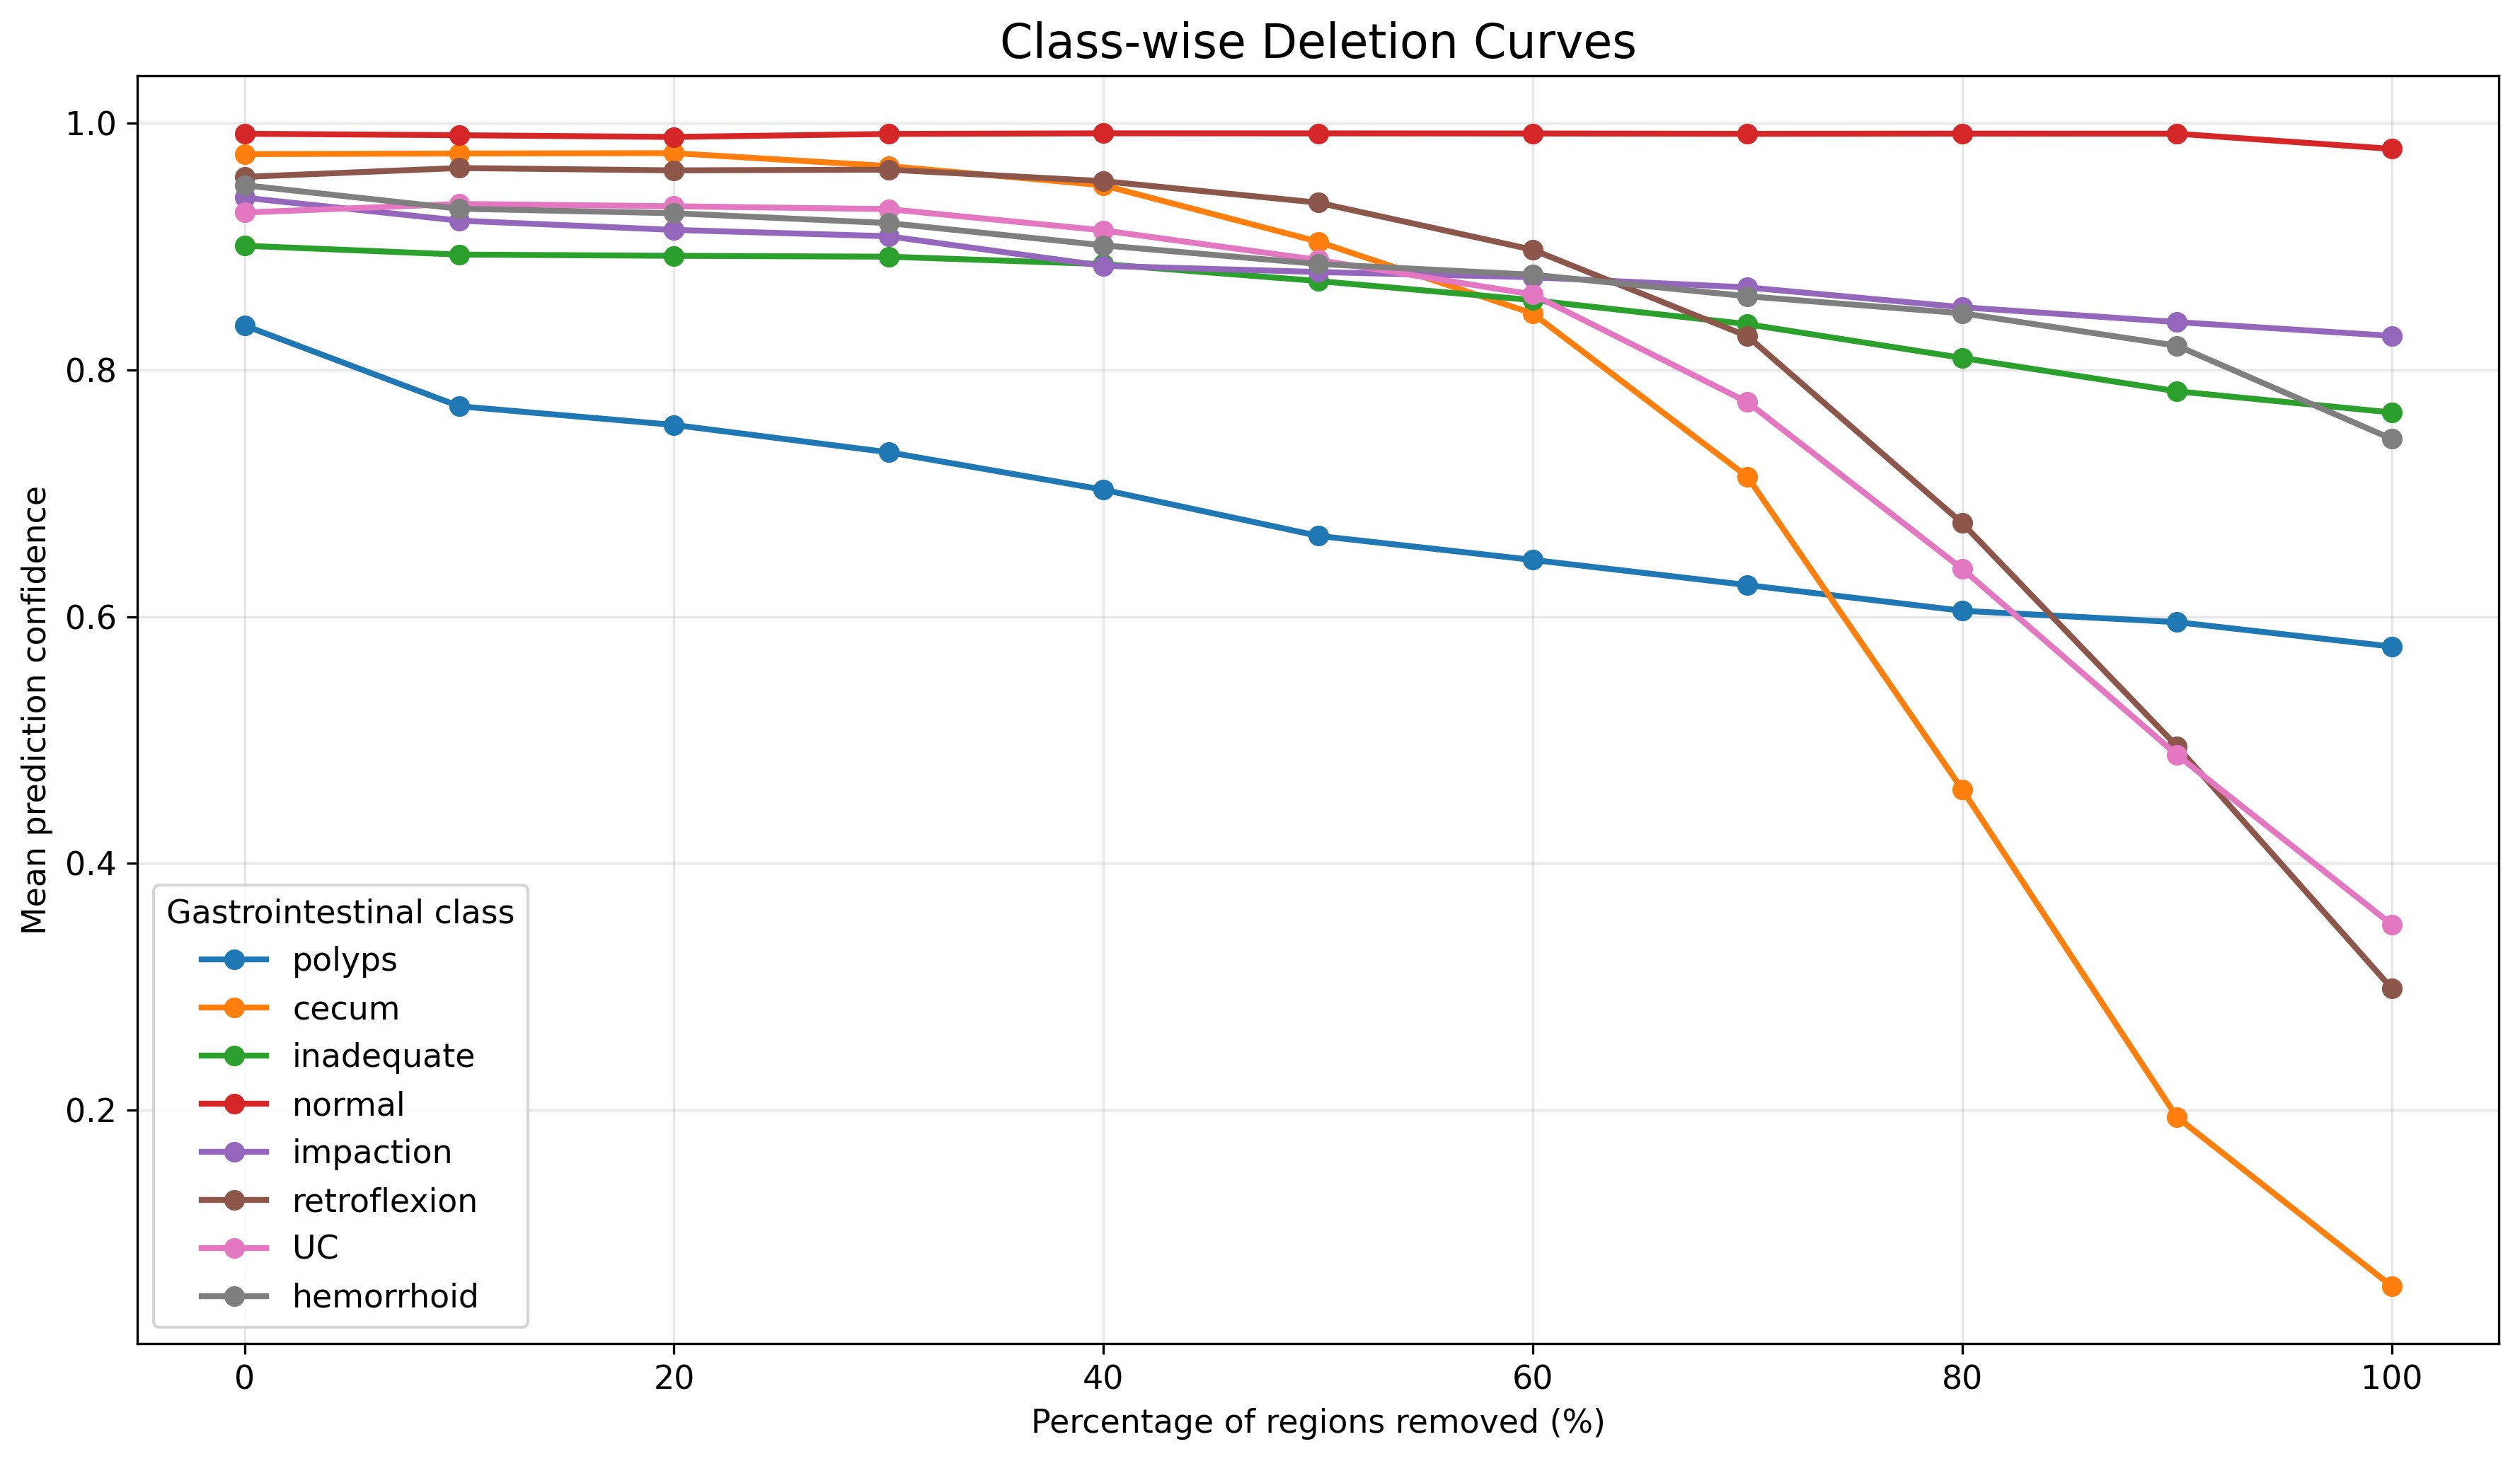

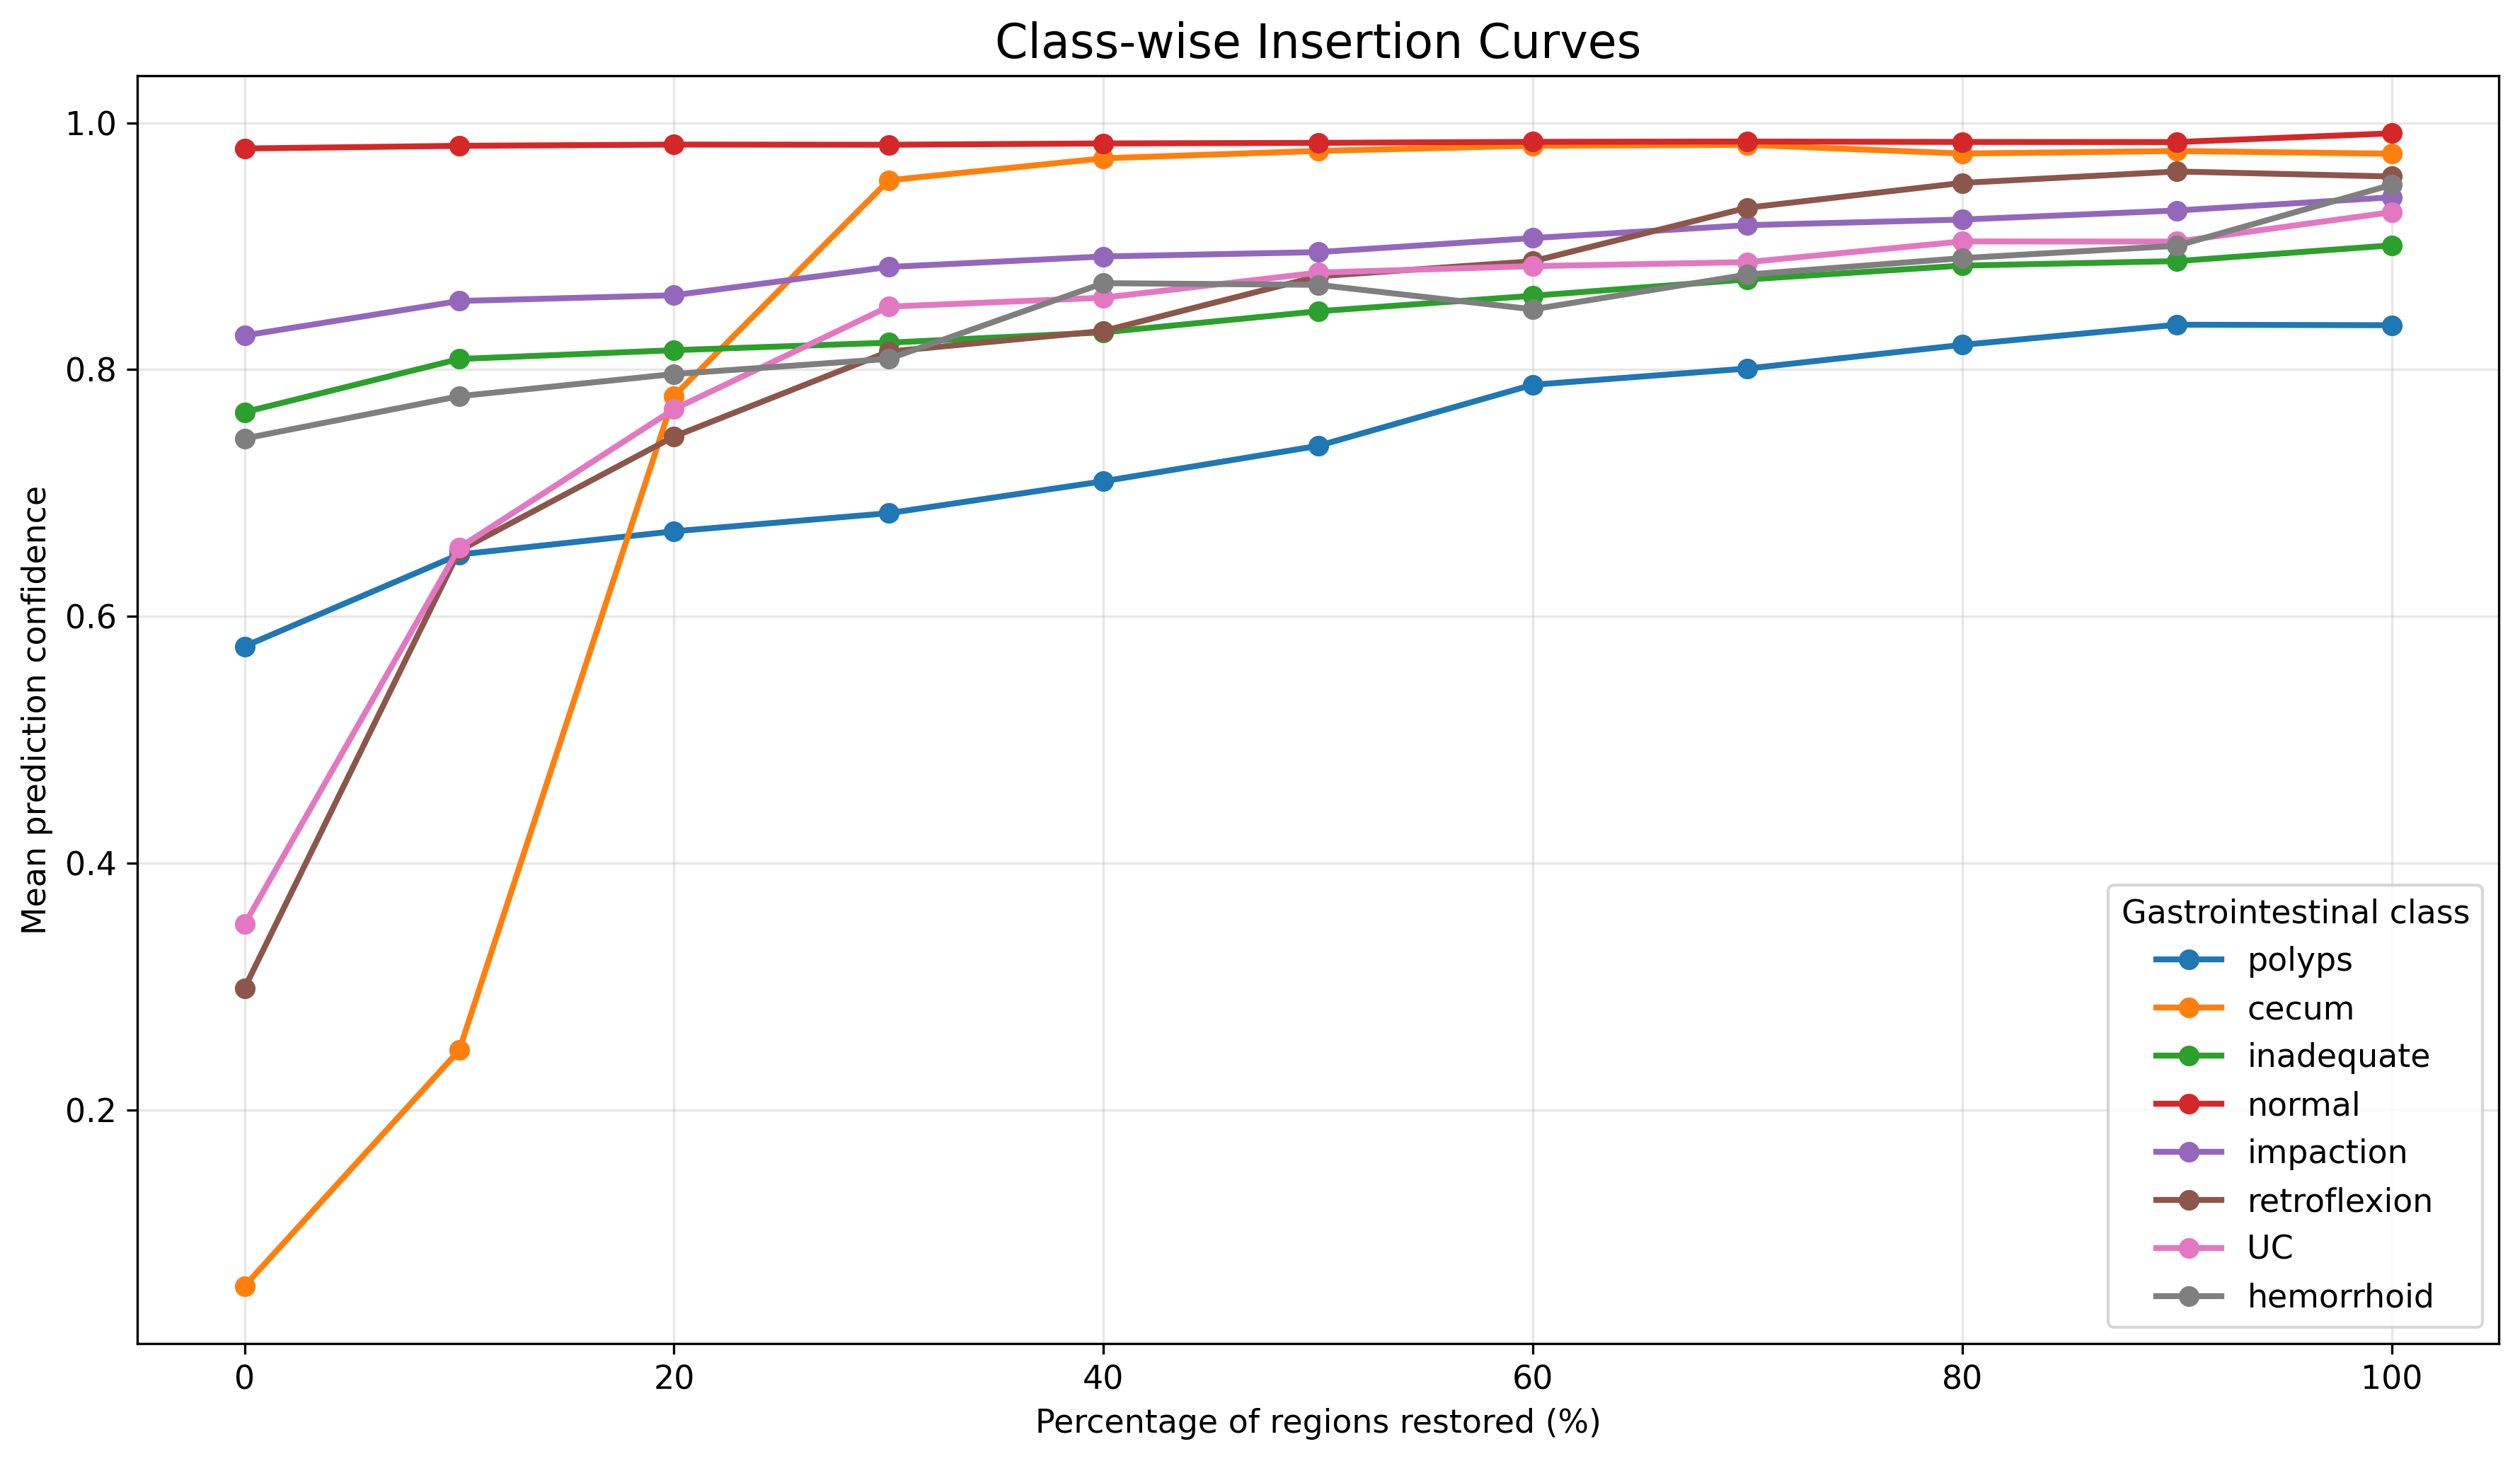

In [138]:
from IPython.display import display, Image

display(Image(filename="/content/XAI_Project/Evaluation_Results/Classwise_Deletion_Insertion_Curves/Classwise_Deletion_Curves.png"))

display(Image(filename="/content/XAI_Project/Evaluation_Results/Classwise_Deletion_Insertion_Curves/Classwise_Insertion_Curves.png"))

Download both graphs

In [140]:
from google.colab import files

files.download(
    "/content/XAI_Project/Evaluation_Results/Classwise_Deletion_Insertion_Curves/Classwise_Deletion_Curves.png"
)

files.download(
    "/content/XAI_Project/Evaluation_Results/Classwise_Deletion_Insertion_Curves/Classwise_Insertion_Curves.png"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [141]:
from google.colab import files

files.download(
    "/content/XAI_Project/Evaluation_Results/Classwise_Deletion_Insertion_Curves/Classwise_Deletion_Curves.png"
)

files.download(
    "/content/XAI_Project/Evaluation_Results/Classwise_Deletion_Insertion_Curves/Classwise_Insertion_Curves.png"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [144]:
import shutil
from google.colab import files

folder = "/content/XAI_Project/Evaluation_Results/Classwise_Deletion_Insertion_Curves"

zip_path = shutil.make_archive(
    "/content/Classwise_XAI_Curves",
    "zip",
    folder
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>